# 02 · Functional PCA baseline

**Advanced movement representation learning — chapter 2.** Status: `AUTHORED — AWAITING USER EXECUTION` (2026-10-11). No cell has been run by the author.

## Research question
**Can functional representations of Combine sprint trajectories capture repeatable athlete characteristics beyond official Combine measurements?**

Functional PCA is the low-complexity benchmark the sequence models (TCN, GRU/LSTM) will have to beat. It is not assumed to beat the official forty: the notebook measures whether its components are repeatable, whether the stopwatch already explains them, and whether they follow the recording instead of the athlete.

## Method in short
1. **Preprocessing checkpoint** closing notebook 01: executable checks, per-sequence censoring indicators, decisions with their justification.
2. **Three representations** of the forty: A speed against recorded distance (primary), B tangential acceleration against speed in the rising phase (secondary), C speed against elapsed time (control). One alternate alignment each, for sensitivity.
3. **Functional PCA with partial coverage**, fitted inside every outer training fold of the split registry and applied to the held-out athletes (inductive). 2, 3, 5 and 8 components are compared; nothing else is tuned.
4. **Evaluation** on out-of-fold scores: explained variance, held-out reconstruction, repeat-attempt reliability (pooled, within position, within cohort), stopwatch redundancy, body measurements, dependence on the recording window and on censoring, sensitivity to the alignment, stability across training folds.
5. **Research gate**: rule-based labels and a proposal for the benchmark representation, for review.

## Inputs (same `RUN_MODE` as notebooks 00 and 01)
`sequence_manifest`, `athlete_registry`, `split_registry` (notebook 00); `sequence_frames`, `sequence_summary`, `alignment_comparison` (notebook 01).

## What this notebook does not do
No NFL value is read, and no NFL outcome chooses a component. Nothing is extrapolated beyond a recording without being labelled model-implied. The warehouse and the kinematic features are not rebuilt.

## Configuration

In [1]:
RUN_MODE = 'full'       # 'smoke' | 'full' — must match the mode notebooks 00 and 01 were run with
FORCE_REBUILD = False
SAVE_FIGURES = True
SAVE_TABLES = True
SAVE_MODELS = True
DEVICE = 'auto'          # unused here (FPCA is NumPy); kept so every notebook has the same controls
SEED = 20261011
NUM_WORKERS = 0
BATCH_SIZE = 32
MAX_EPOCHS = 3

In [2]:
from dataclasses import asdict

from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.features.config import KinematicsConfig
from nflbdb.research.advanced_movement import alignment as al
from nflbdb.research.advanced_movement import checkpoint as ck
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import data as amd
from nflbdb.research.advanced_movement import eda
from nflbdb.research.advanced_movement import fpca as fp
from nflbdb.research.advanced_movement import fpca_eval as fe
from nflbdb.research.advanced_movement import fpca_figures as ff
from nflbdb.research.advanced_movement import fpca_validation
from nflbdb.research.advanced_movement import sequences as seq
from nflbdb.research.advanced_movement.artifacts import AdvStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES,
                                save_tables=SAVE_TABLES, save_models=SAVE_MODELS, device=DEVICE, seed=SEED,
                                num_workers=NUM_WORKERS, batch_size=BATCH_SIZE, max_epochs=MAX_EPOCHS).validate()
acfg = amc.AdvancedConfig().for_mode(controls)
fcfg = fp.FpcaConfig().for_mode(controls)
store = AdvStore(cfg, controls)
pl.Config.set_tbl_rows(80)
pl.Config.set_tbl_cols(24)
pl.Config.set_fmt_str_lengths(240)

# Prerequisites: artifacts of notebooks 00 and 01 in the SAME run mode (smoke artifacts are never used for a full run).
NB00, NB01 = '00_research_setup_and_data_audit.ipynb', '01_sequence_eda_and_alignment.ipynb'
manifest = store.require(amd.MANIFEST, NB00)
athletes = store.require(amd.ATHLETES, NB00)
splits = store.require(amd.SPLITS, NB00)
seq_frames = store.require(seq.SEQ_FRAMES, NB01)
summary = store.require(eda.SUMMARY, NB01)
comparison = store.require(al.COMPARISON, NB01)
previous = store.read_json('research_metadata', NB00)
if previous.get('seed') != controls.seed:
    seed_00 = previous.get('seed')
    raise ValueError(f'SEED = {controls.seed} but notebook 00 was run with seed {seed_00}: use the same seed')

ss = seq.SequenceSet.from_frames(seq_frames, manifest)
half_window = KinematicsConfig().smoothing.window // 2     # Savitzky–Golay half-window of the persisted kinematics
names = dict(athletes.select('nfl_id', 'display_name').iter_rows())
position_of = dict(athletes.select('nfl_id', 'position_group').iter_rows())
MAIN = [s.name for s in fp.MAIN]
n_repeats, n_folds = splits['repeat'].n_unique(), splits['outer_fold'].n_unique()
display(Markdown(f'**Run mode: `{controls.run_mode}`** · {ss.n} sequences of {np.unique(ss.nfl_ids).size} athletes · '
                 f'{n_repeats} split repeat(s) × {n_folds} outer folds'))
display(store.describe())

**Run mode: `full`** · 793 sequences of 418 athletes · 3 split repeat(s) × 5 outer folds

what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_movement"""
"""datasets (Parquet + schema sidecar)""","""warehouse/gold/advanced_movement"""
"""figures (PNG 300 DPI, SVG, PDF)""","""reports/figures/advanced_movement"""
"""models and fitted preprocessing""","""artifacts/models/advanced_movement"""


### Synthetic validation of the code used below

Nine checks on synthetic data with a known answer (two known functional modes; analytic sprint curves). They run in this kernel, touch no warehouse file, and stop the notebook if one fails.

In [3]:
validation_report = fpca_validation.run_all()
display(validation_report)
fpca_validation.assert_all_passed(validation_report)

15:18:11 | INFO    | nflbdb.research.advanced_movement.fpca_eval | [advanced_movement:FPCA] A_speed_by_distance: 9 fits, support 76 of 81 grid points
15:18:11 | INFO    | nflbdb.research.advanced_movement.fpca_eval | [advanced_movement:FPCA] B_accel_by_speed: 9 fits, support 13 of 43 grid points
15:18:11 | INFO    | nflbdb.research.advanced_movement.fpca_eval | [advanced_movement:FPCA] C_speed_by_time: 9 fits, support 46 of 61 grid points
15:18:11 | INFO    | nflbdb.research.advanced_movement.fpca_eval | [advanced_movement:FPCA] A_alt_origin_at_ref_speed: 9 fits, support 75 of 81 grid points
15:18:13 | INFO    | nflbdb.research.advanced_movement.fpca_eval | [advanced_movement:FPCA] no fitted models on disk for this configuration: refitting in memory
15:18:13 | INFO    | nflbdb.research.advanced_movement.fpca_eval | [advanced_movement:FPCA] A_speed_by_distance: 9 fits, support 76 of 81 grid points
15:18:13 | INFO    | nflbdb.research.advanced_movement.fpca_eval | [advanced_movement:FPCA

check,status,detail
str,str,str
"""basis_and_small_helpers""","""PASS""","""B-splines sum to one, quadrature integrates the grid, athlete weights and attempt pairing are correct"""
"""fpca_recovers_known_modes""","""PASS""","""both known modes are recovered (congruence 0.998, 0.998); scores track the true scores"""
"""partial_coverage_is_never_filled""","""PASS""","""unrecorded points never enter a fit, a score or an error; a poorly covered tail leaves the support"""
"""fit_uses_training_athletes_only""","""PASS""","""held-out athletes cannot move a fit; repeating an athlete's attempts does not change his weight"""
"""sign_order_and_persistence""","""PASS""","""fold fits take the sign and order of the reference without changing a value; models reload identically"""
"""representations_from_sequences""","""PASS""","""six representations are built; values stop where the recording stops and at masked boundary frames"""
"""preprocessing_audit""","""PASS""","""the audit passes on clean data and reports a planted extrapolation and a manifest built on the fallback"""
"""fold_loop_and_evaluation""","""PASS""","""4 representations × 8 inductive fits: every attempt is scored once by a fit that excluded its athlete; all evaluation tables satisfy their contracts"""
"""gate_rules""","""PASS""","""labels follow the intervals, a straddling interval stays inconclusive, K is chosen without any outcome"""


## 1 · Preprocessing checkpoint (closing notebook 01)

The curves of the six representations are built here once: three main, three alternates. Each is a linear interpolation inside one sequence; a grid point outside the recorded range is missing, never filled.

The audit below checks, on the data of this run:

| Property | Check |
|---|---|
| Original timestamps | the original clock increases on every frame; `t_rel` is that clock minus its first frame; sampling regularity is reported |
| Real versus padded frames | padded cells are zero and masked |
| Channel-specific missingness | the axis channels are always defined; shares of undefined frames per channel |
| Derivative boundaries | boundary frames are flagged on both edges of every sequence |
| Censoring indicators | first-frame and last-frame indicators are defined for every sequence; the production manifest carries the sprint-rescue flags |
| Alignment coverage masks | every observed grid value maps to an original time inside the recording (no extrapolation), per representation |
| Split integrity | the leakage audit of notebook 00 re-run on the registry as loaded |

A failed **blocking** check stops the notebook. Train-fold-only normalisation is enforced where it happens: every fold fit asserts that it has not seen the athletes it scores (section 4), and the synthetic check above shows that held-out athletes cannot move a fit.

In [4]:
curves = {s.name: fp.build_curves(ss, acfg, s) for s in fp.REPRESENTATIONS}


def build_checkpoint():
    w = ck.sequence_windows(ss, summary, manifest, acfg, fcfg)
    return {ck.WINDOWS.name: w,
            ck.AUDIT.name: ck.audit_preprocessing(ss, seq_frames, manifest, splits, w, curves, acfg, half_window)}


REPRESENTATION_PARAMS = [asdict(s) for s in fp.REPRESENTATIONS]
built = store.build('CHECKPOINT', [ck.WINDOWS, ck.AUDIT], build_checkpoint,
                    params={'config': acfg.params(), 'fpca': fcfg.params(), 'half_window': half_window,
                            'representations': REPRESENTATION_PARAMS},
                    files=[store.parquet(seq.SEQ_FRAMES), store.parquet(amd.MANIFEST), store.parquet(amd.SPLITS),
                           store.parquet(eda.SUMMARY)])
windows, audit = built[ck.WINDOWS.name], built[ck.AUDIT.name]
display(audit)
ck.assert_blocking_passed(audit)

display(Markdown('**Recording window and censoring indicators** (unit: sequence; shares of sequences)'))
display(ck.window_summary(windows))
display(Markdown('**Extreme recordings** — kept, not removed; a few of them can dominate a within-athlete variance on a small subset'))
display(ck.extreme_recordings(windows, splits))

15:18:15 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:CHECKPOINT] computing (never run)
15:18:15 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:CHECKPOINT] sequence_window_flags: 793 rows → warehouse/gold/advanced_movement/sequence_window_flags.parquet
15:18:15 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:CHECKPOINT] preprocessing_audit: 22 rows → warehouse/gold/advanced_movement/preprocessing_audit.parquet


check,passed,blocking,n_violations,detail
str,bool,bool,i64,str
"""original_clock_strictly_increasing""",true,true,0,"""t_s (seconds since the trajectory's first valid frame, Phase 03) increases on every frame of every sequence"""
"""t_rel_is_original_clock_minus_first_frame""",true,true,0,"""t_rel = t_s − t_s of frame 0; the original clock is kept beside it in sequence_frames and on every aligned grid"""
"""regular_sampling_inside_sequences""",true,false,0,"""0 of 40707 frame steps differ from 0.1 s; every alignment interpolates on the recorded clock, so an irregular step is used as recorded, not assumed regular"""
"""padding_is_zero_and_masked""",true,true,0,"""41,500 real frames and 29,870 padded cells in 793 sequences; padded cells are exactly zero, flagged by `mask`, and aligned curves hold NaN (not zero) outside the recording"""
"""fpca_axis_channels_always_defined""",true,true,0,"""undefined real frames of t_rel / dist / speed; shares of undefined real frames per channel: t_rel 0.00 %, dist 0.00 %, along 0.00 %, speed 0.00 %, a_tan 0.03 %, a_lat 0.03 %, yaw_rate 3.45 %, lat_dev 0.00 %, head_sin 3.45 %, head_cos 3.45 %…"
"""boundary_frames_flagged_on_both_edges""",true,false,0,"""sequences whose flagged boundary frames differ from 2 × 3 (the Savitzky–Golay half-window at each edge); median share of boundary frames per sequence 0.118"""
"""sprint_rescue_flags_present""",true,true,0,"""eligible sequences without sprint-rescue flags (793 checked). Non-zero means the manifest was built on the quality-tier fallback: rerun the sprint rescue, then notebook 00"""
"""censoring_indicators_complete""",true,true,0,"""sequences with an undefined first-frame or last-frame censoring indicator"""
"""no_value_outside_the_recording:A_speed_by_distance""",true,true,0,"""grid values whose original time is unknown or outside [first frame, last frame] — any would be an extrapolation"""


**Recording window and censoring indicators** (unit: sequence; shares of sequences)

cohort,sequences,athletes,first_frame_censored,start_above_ref_speed,last_frame_censored,ends_at_peak,signal_flag,boundary_peak,median_first_speed,median_duration_s,median_frames_after_peak
str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""ALL""",793,418,0.58512,0.003783,0.831021,0.281211,0.07314,0.153846,0.561925,5.0,4.0
"""2023""",262,138,0.534351,0.0,0.870229,0.335878,0.0,0.072519,0.515285,5.0,4.0
"""2024""",269,147,0.717472,0.007435,0.754647,0.215613,0.171004,0.189591,0.657354,5.0,5.0
"""2025""",262,133,0.5,0.003817,0.870229,0.293893,0.045802,0.198473,0.5245,5.1,4.0


**Extreme recordings** — kept, not removed; a few of them can dominate a within-athlete variance on a small subset

why,seq_id,position_group,draft_year,attempt_order,n_frames,duration_s,first_speed,frames_after_peak,path_yd,design_role
str,str,str,i64,i64,i64,f64,f64,i64,f64,str
"""longest recording""","""64066606e3d8e72dcd850840-2023|55999|4""","""DB""",2023,2,90,8.9,0.875546,5,43.224918,"""design"""
"""longest recording""","""20240301100300_1709324534663_000|57164|1""","""DB""",2024,1,63,6.2,1.509841,0,43.848621,"""design"""
"""longest recording""","""20240303101000_1709497471519_000|57207|1""","""OL""",2024,1,63,6.2,0.522184,6,41.714966,"""design"""
"""longest recording""","""20240303100900_1709490621288_000|57293|1""","""OL""",2024,1,62,6.1,0.71913,7,41.861073,"""confirm"""
"""longest recording""","""20250302101000_1740945931547_000|58987|1""","""OL""",2025,1,62,6.1,0.526396,4,40.396942,"""confirm"""
"""latest start""","""20250228100500_1740788639426_000|58950|2""","""TE""",2025,1,50,4.9,3.360816,6,41.062328,"""confirm"""
"""latest start""","""20240303101000_1709497664752_000|57353|1""","""OL""",2024,1,61,6.0,3.003022,10,41.691582,"""confirm"""
"""latest start""","""20240303101000_1709498130159_000|57240|2""","""OL""",2024,2,52,5.1,2.278293,6,40.631294,"""confirm"""
"""latest start""","""20240302100700_1709411956932_000|57291|2""","""WR""",2024,2,51,5.0,1.893007,7,40.930923,"""confirm"""


### The sprint-rescue fallback warning

Notebook 00 printed `sprint-rescue attempt table missing: usable tier taken from quality_tier` eleven times. Every occurrence is in the output of its **synthetic-validation cell**: the fixtures build a manifest without a sprint-rescue table on purpose, once per fixture. The production census cell printed no such line, and its manifest carries the flags on every eligible sequence (`dataset_audit.csv`, section `flags_primary_eligible`: 793 sequences with each flag in the full run).

Two corrections were authored: the fixtures now declare the fallback as intended, so the warning no longer appears during validation; and the check `sprint_rescue_flags_present` above is blocking, so a production manifest built on the fallback stops this notebook.

### A reading of the notebook 01 comparison

On the clock-based alignments the design subset is far less repeatable than the other athletes (speed by elapsed time: 0.23 against 0.58, position-adjusted, full run), because its within-athlete variance is about four times larger. State- and distance-anchored curves do not show that gap. The table of extreme recordings above shows which athletes hold the longest recordings and the latest starts, and their role. This is why the clock is the control here, not the primary axis.

### Decisions

The Milestone 2 brief fixes the three representations, which supersedes the single `alignment` choice left pending in notebook 01. The other choices are either verified by the audit or proposed starting assumptions, and are labelled as such. The evidence column is computed from this run.

In [5]:
detail = dict(zip(audit['check'].to_list(), audit['detail'].to_list()))
adjusted = comparison.filter(pl.col('scope') == 'position_adjusted')


def show3(v):
    return 'n/a' if v is None else f'{v:.3f}'


def pct(v):
    return 'n/a' if v is None else f'{100 * v:.1f} %'


def icc_text(method, channel):
    rows = adjusted.filter((pl.col('method') == method) & (pl.col('channel') == channel))
    got = dict(zip(rows['athlete_set'].to_list(), rows['icc_integrated'].to_list()))
    d, c = got.get('design'), got.get('confirm')
    return f'{channel} by {method}: design {show3(d)}, confirm {show3(c)}'


def repeats(frame):
    return frame.group_by('nfl_id').len().filter(pl.col('len') >= 2).height


everything = ck.window_summary(windows).row(0, named=True)
coverage_text = '; '.join(f'{k.split(":")[1]}: {v}' for k, v in detail.items() if k.startswith('coverage:'))
censor_text = (f'starts in motion {pct(everything["first_frame_censored"])}, starts above the reference speed '
               f'{pct(everything["start_above_ref_speed"])}, ends at top speed {pct(everything["last_frame_censored"])}, '
               f'peak on the last frame {pct(everything["ends_at_peak"])} of {windows.height} sequences')
scenario_text = (f'athletes with a repeat: S0_all {repeats(windows)}, '
                 f'S2_signal {repeats(windows.filter(pl.col("S2_signal").fill_null(False)))}, '
                 f'S3_no_boundary {repeats(windows.filter(pl.col("S3_no_boundary").fill_null(False)))}')
evidence = {
    'representations': 'notebook 01, integrated ICC of the aligned curve, position-adjusted — '
                       + '; '.join([icc_text('distance', 'speed'), icc_text('speed_phase', 'a_tan'), icc_text('elapsed_time', 'speed')]),
    'input_channels': detail['fpca_axis_channels_always_defined'],
    'original_timestamps': detail['original_clock_strictly_increasing'] + ' · ' + detail['regular_sampling_inside_sequences'],
    'censoring_indicators': censor_text,
    'real_versus_padded_frames': detail['padding_is_zero_and_masked'],
    'channel_missingness': detail['fpca_axis_channels_always_defined'],
    'derivative_boundaries': detail['boundary_frames_flagged_on_both_edges'],
    'partial_coverage': coverage_text,
    'quality_scenario': scenario_text,
    'normalisation': 'synthetic check fit_uses_training_athletes_only (above) and the leakage assertion of every fold fit (section 4)',
    'split_integrity': detail['split_registry_passes_the_leakage_audit'],
    'sprint_rescue_fallback_warning': detail['sprint_rescue_flags_present'],
}
decisions = ck.final_decisions(evidence)
if controls.save_tables:
    decisions = store.write(decisions, ck.DECISIONS, 'CHECKPOINT', {'run_mode': controls.run_mode, 'seed': controls.seed})
display(decisions.select('decision', 'choice', 'status'))
display(decisions.select('decision', 'justification', 'evidence'))

15:18:15 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:CHECKPOINT] preprocessing_decisions_final: 12 rows → warehouse/gold/advanced_movement/preprocessing_decisions_final.parquet


decision,choice,status
str,str,str
"""representations""","""A speed against recorded distance (primary) · B tangential acceleration against speed, rising phase (secondary) · C speed against elapsed time (control)""","""DECIDED (brief)"""
"""input_channels""","""speed and a_tan as values; dist, speed and t_rel as axes; no lateral channel""","""PROPOSED — open to review"""
"""original_timestamps""","""kept: t_s per frame in sequence_frames, t_orig per grid point on every aligned curve""","""DECIDED (verified)"""
"""censoring_indicators""","""carried per sequence as diagnostics (sequence_window_flags); never a filter, never a model input""","""DECIDED (verified)"""
"""real_versus_padded_frames""","""padded cells are zero and masked in the sequence array; aligned curves are NaN outside the recording""","""DECIDED (verified)"""
"""channel_missingness""","""no imputation; an undefined frame leaves the neighbouring grid points undefined""","""DECIDED (verified)"""
"""derivative_boundaries""","""a_tan is masked on smoothing-boundary frames in B (kept in the alternate B′); speed keeps every frame""","""PROPOSED — open to review"""
"""partial_coverage""","""support = longest run of grid points observed for ≥ 80 % of the training weight; a curve is scored when it covers ≥ 50 % of the support; scores are best linear predictions from its observed points""","""PROPOSED — open to review"""
"""quality_scenario""","""S0_all for fitting and for the primary evaluation; S2_signal and S3_no_boundary as reliability sensitivities""","""PROPOSED — open to review"""


decision,justification,evidence
str,str,str
"""representations""","""Fixed by the Milestone 2 brief; it supersedes the single `alignment` choice left pending in notebook 01. C is kept as the control because the recording clock starts at an arbitrary moment of the run.""","""notebook 01, integrated ICC of the aligned curve, position-adjusted — speed by distance: design 0.754, confirm 0.837; a_tan by speed_phase: design 0.364, confirm 0.416; speed by elapsed_time: design 0.230, confirm 0.575"""
"""input_channels""","""FPCA is fitted one channel at a time. a_lat, lat_dev, yaw_rate and head_sin change sign under a mirror image of the run and the handedness of the Combine frame is unverified, so they are left out.""","""undefined real frames of t_rel / dist / speed; shares of undefined real frames per channel: t_rel 0.00 %, dist 0.00 %, along 0.00 %, speed 0.00 %, a_tan 0.03 %, a_lat 0.03 %, yaw_rate 3.45 %, lat_dev 0.00 %, head_sin 3.45 %, head_cos 3.45 %…"
"""original_timestamps""","""An aligned value can always be traced back to its frames; no representation replaces the clock.""","""t_s (seconds since the trajectory's first valid frame, Phase 03) increases on every frame of every sequence · 0 of 40707 frame steps differ from 0.1 s; every alignment interpolates on the recorded clock, so an irregular step is used as reco…"
"""censoring_indicators""","""Phase 03 `end_censored` is true for every forty attempt, so the continuous window variables and four explicit flags are used instead. Filtering on them would select athletes by how they were recorded.""","""starts in motion 58.5 %, starts above the reference speed 0.4 %, ends at top speed 83.1 %, peak on the last frame 28.1 % of 793 sequences"""
"""real_versus_padded_frames""","""A padded or unrecorded cell is never an observation: means, covariances and scores use observed points only.""","""41,500 real frames and 29,870 padded cells in 793 sequences; padded cells are exactly zero, flagged by `mask`, and aligned curves hold NaN (not zero) outside the recording"""
"""channel_missingness""","""The axis channels are always defined; a_tan is undefined on a handful of frames, which interpolation does not bridge.""","""undefined real frames of t_rel / dist / speed; shares of undefined real frames per channel: t_rel 0.00 %, dist 0.00 %, along 0.00 %, speed 0.00 %, a_tan 0.03 %, a_lat 0.03 %, yaw_rate 3.45 %, lat_dev 0.00 %, head_sin 3.45 %, head_cos 3.45 %…"
"""derivative_boundaries""","""Acceleration is a second derivative of a locally fitted polynomial and is least reliable at the segment edges (Phase 03 A3: peaks concentrate on boundary frames). Dropping the same frames for speed would remove the start and the end of ever…","""sequences whose flagged boundary frames differ from 2 × 3 (the Savitzky–Golay half-window at each edge); median share of boundary frames per sequence 0.118"""
"""partial_coverage""","""Nothing is extrapolated to fit or to score. A reconstruction outside a curve's recorded range is model-implied, labelled as such, and excluded from every error.""","""A_speed_by_distance: 99.7 % of grid points × sequences observed; 0 of 793 sequences have no value on the grid and cannot be scored; B_accel_by_speed: 79.5 % of grid points × sequences observed; 0 of 793 sequences have no value on the grid a…"
"""quality_scenario""","""Stricter scenarios cost repeated athletes and select on signal quality; they are reported, not applied.""","""athletes with a repeat: S0_all 375, S2_signal 333, S3_no_boundary 254"""


## 2 · Functional PCA with partly recorded curves

A curve $y_i(t)$ is known only where the recording holds data: $o_i(t) = 1$ there, $0$ elsewhere. Everything below is estimated on the sequences of the **training athletes of a fold**; each athlete has weight 1, shared by his attempts ($w_i$).

- **Support.** The longest run of grid points observed for at least 80 % of the training weight. The model is defined there and nowhere else.
- **Mean.** $\hat\mu(t)$ = weighted mean of the curves observed at $t$.
- **Covariance.** Pairwise-complete:
$$\hat C(s,t)=\frac{\sum_i w_i\,o_i(s)\,o_i(t)\,\big(y_i(s)-\hat\mu(s)\big)\big(y_i(t)-\hat\mu(t)\big)}{\sum_i w_i\,o_i(s)\,o_i(t)}$$
- **Functional basis.** Clamped cubic B-splines on the support. $\hat C$ is projected on the basis and the eigenproblem is solved in the $L^2$ metric, which gives smooth eigenfunctions $\phi_k$ with $\int \phi_k^2 = 1$ and variances $\lambda_k$.
- **Scores.** For a curve observed at the points $o_i$, with $F_i$ the eigenfunctions at those points and $\hat\sigma^2$ the variance per point left after $K$ components:
$$\hat\xi_i=\Big(F_i^\top F_i/\hat\sigma^2+\Lambda^{-1}\Big)^{-1}F_i^\top\big(y_i-\hat\mu\big)_{o_i}/\hat\sigma^2$$
the best linear prediction of the scores from the recorded part (Yao, Müller and Wang, 2005). A curve covering less than half of the support gets no score.
- **Reconstruction.** $\hat\mu + \sum_k \hat\xi_{ik}\phi_k$ on the support. Where the curve was not recorded this is a model-implied value: it is drawn dotted, named as such, and excluded from every error.

**Inductive evaluation.** For each split repeat and outer fold the model is fitted without the held-out athletes and then scores them. One extra fit on all athletes (the *reference*, transductive) only fixes the sign and the order of the components so that scores of different folds are comparable, and is used for the descriptive mode plots.

**Tuning budget.** The number of components is the only quantity compared: 2, 3, 5, 8. Fixed before any fit and not tuned: one basis size per representation, the 80 % support rule, the 50 % scoring rule, the scoring method. That is 4 settings × 3 representations, plus the same 4 for each alternate alignment.

**A limit to keep in mind.** In representation B a high speed level is missing exactly for the athletes who never reach it, so missingness is informative there. The support rule keeps only the speed levels most training athletes reach, and the share of the support each attempt covers is tested as a nuisance variable in section 9.

In [6]:
display(pl.DataFrame([{'representation': s.name, 'role': s.role, 'value': s.channel, 'axis': s.axis_label, 'origin': s.origin,
                       'boundary_frames_masked': s.mask_boundary, 'n_basis': s.n_basis, 'what_changes': s.what_changes}
                      for s in fp.REPRESENTATIONS]))
display(pl.DataFrame([{'representation': n, 'grid_points': int(c.grid.size), 'sequences_with_a_curve': int(c.mask.any(1).sum()),
                       'athletes_with_a_curve': int(np.unique(c.nfl_ids[c.mask.any(1)]).size),
                       'share_of_grid_observed': float(c.mask.mean())} for n, c in curves.items()]))
display(pl.DataFrame([{'parameter': k, 'value': str(v)} for k, v in fcfg.params().items()]))

representation,role,value,axis,origin,boundary_frames_masked,n_basis,what_changes
str,str,str,str,str,bool,i64,str
"""A_speed_by_distance""","""primary""","""speed""","""path length since the first recorded frame (yd)""","""recording""",false,16,""""""
"""B_accel_by_speed""","""secondary""","""a_tan""","""speed level reached (yd/s)""","""recording""",true,10,""""""
"""C_speed_by_time""","""control""","""speed""","""time since the first recorded frame (s)""","""recording""",false,16,""""""
"""A_alt_origin_at_ref_speed""","""alternate""","""speed""","""path length since the reference speed was reached (yd)""","""reference_speed""",false,16,"""origin = the moment speed first reaches the reference speed, not the first recorded frame"""
"""B_alt_boundary_kept""","""alternate""","""a_tan""","""speed level reached (yd/s)""","""recording""",false,10,"""acceleration on the smoothing-boundary frames is kept instead of masked"""
"""C_alt_origin_at_ref_speed""","""alternate""","""speed""","""time since the reference speed was reached (s)""","""reference_speed""",false,16,"""origin = the moment speed first reaches the reference speed, not the first recorded frame"""


representation,grid_points,sequences_with_a_curve,athletes_with_a_curve,share_of_grid_observed
str,i64,i64,i64,f64
"""A_speed_by_distance""",81,793,418,0.997213
"""B_accel_by_speed""",43,793,418,0.79539
"""C_speed_by_time""",61,793,418,0.857172
"""A_alt_origin_at_ref_speed""",81,790,418,0.98837
"""B_alt_boundary_kept""",43,793,418,0.882108
"""C_alt_origin_at_ref_speed""",61,790,418,0.787588


parameter,value
str,str
"""version""","""1"""
"""k_grid""","""(2, 3, 5, 8)"""
"""degree""","""3"""
"""min_coverage""","""0.8"""
"""min_observed_fraction""","""0.5"""
"""score_method""","""blup"""
"""ridge""","""1e-08"""
"""fve_target""","""0.95"""
"""last_frame_speed_fraction""","""0.98"""


## 3 · Mean curves by position

Descriptive, all athletes, no model. Position groups differ in speed by a wide margin, so a pooled component can be repeatable only because it encodes position: every reliability and redundancy statistic below is therefore also computed within position.

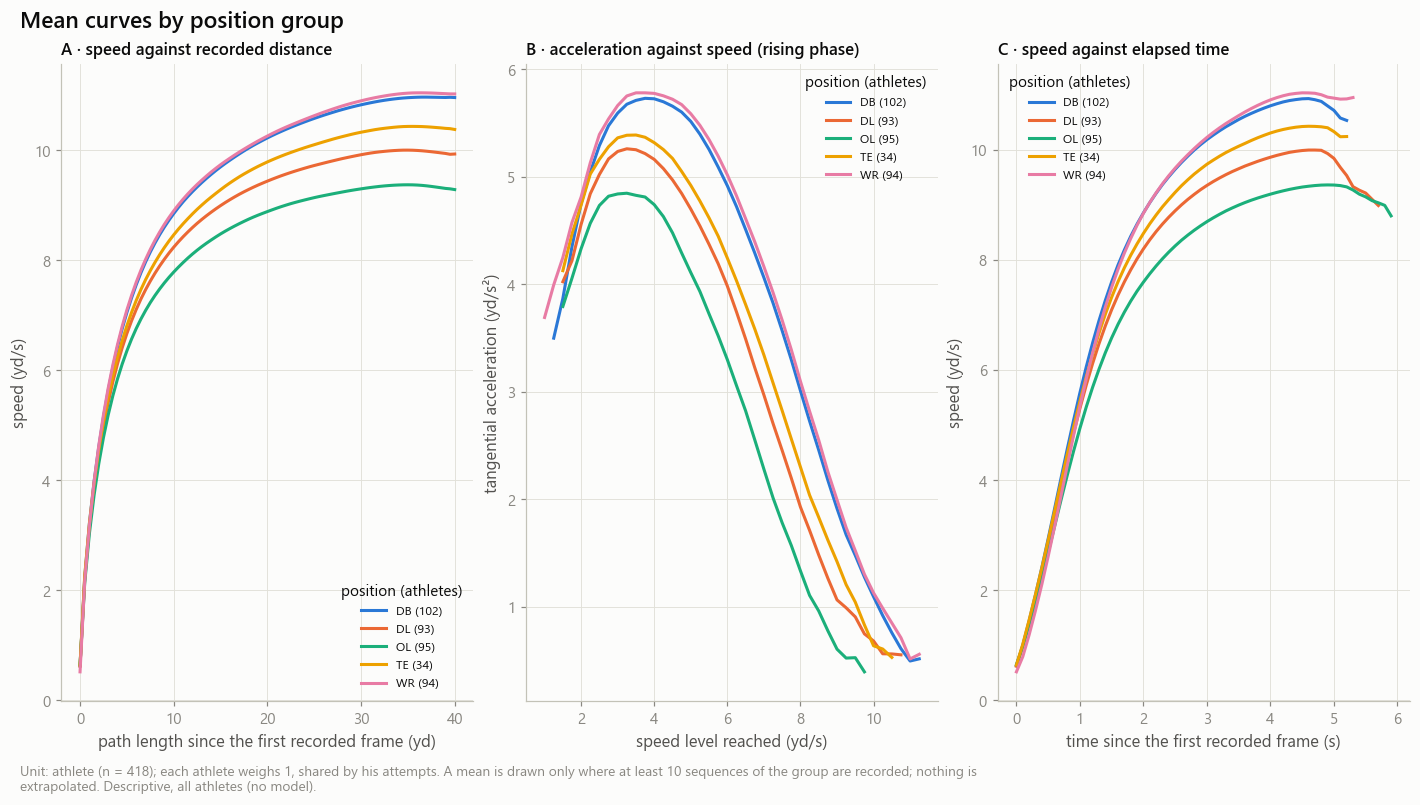

In [7]:
store.show(ff.plot_mean_curves(curves, position_of), 'AM02_01_mean_curves_by_position', source='sequence_frames',
           n=f'{ss.n} sequences of {np.unique(ss.nfl_ids).size} athletes')

## 4 · Fold fits (inductive) and evaluation tables

Three cached stages. Each is restored when its parameters and inputs are unchanged; set `FORCE_REBUILD = True` to recompute.

| Stage | Computes | Uses |
|---|---|---|
| `FPCA_FIT` | reference fit + one fit per split repeat and outer fold, held-out scores and reconstruction errors, for six representations | sequences, split registry |
| `FPCA_EVAL` | explained variance, reconstruction, reliability, stopwatch redundancy, body measurements, window dependence, alignment sensitivity, score stability | fit tables, window flags, official Combine measurements |
| `FPCA_GATE` | benchmark K per representation, per-component labels, representation summary | evaluation tables |

Every fold fit raises a `LeakageError` if one of the athletes it is about to score contributed to it.

In [8]:
FIT_PARAMS = {'config': acfg.params(), 'fpca': fcfg.params(), 'representations': REPRESENTATION_PARAMS,
              'half_window': half_window, 'seed': controls.seed}
FIT_FILES = [store.parquet(seq.SEQ_FRAMES), store.parquet(amd.SPLITS)]
MODEL_KEY = fe.fit_key(FIT_PARAMS, FIT_FILES)
RUNS = {}


def build_fit():
    RUNS.update(fe.fit_all(curves, splits, fcfg))
    if controls.save_models:
        fe.save_runs(store.models_dir, RUNS, MODEL_KEY)
    return fe.fit_tables(RUNS)


fit = store.build('FPCA_FIT', list(fe.FIT_CONTRACTS), build_fit, params=FIT_PARAMS, files=FIT_FILES)
# Fitted models for the figures: from this run, else from disk when saved under the same key, else refitted in memory.
if RUNS:
    models = {name: run.models for name, run in RUNS.items()}
else:
    models = fe.load_or_refit(store.models_dir, curves, splits, fcfg, MODEL_KEY)

fits = fit[fe.FOLD_FITS.name]
display(Markdown('**Fold fits** (all split repeats; support and basis are learned on the training athletes of each fold)'))
display(fits.group_by('representation', 'k').agg(
    pl.len().alias('fold_fits'), pl.col('n_train_athletes').min().alias('train_athletes_min'),
    pl.col('n_test_scored').sum().alias('heldout_attempts_scored'),
    (pl.col('n_test_sequences') - pl.col('n_test_scored')).sum().alias('heldout_attempts_not_scored'),
    pl.col('support_lo').max().alias('support_from_max'), pl.col('support_hi').min().alias('support_to_min'),
    pl.col('n_basis').min().alias('n_basis')).sort('representation', 'k'))

15:18:18 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:FPCA_FIT] computing (never run)


15:18:20 | INFO    | nflbdb.research.advanced_movement.fpca_eval | [advanced_movement:FPCA] A_speed_by_distance: 16 fits, support 81 of 81 grid points
15:18:22 | INFO    | nflbdb.research.advanced_movement.fpca_eval | [advanced_movement:FPCA] B_accel_by_speed: 16 fits, support 30 of 43 grid points
15:18:23 | INFO    | nflbdb.research.advanced_movement.fpca_eval | [advanced_movement:FPCA] C_speed_by_time: 16 fits, support 49 of 61 grid points
15:18:25 | INFO    | nflbdb.research.advanced_movement.fpca_eval | [advanced_movement:FPCA] A_alt_origin_at_ref_speed: 16 fits, support 80 of 81 grid points
15:18:27 | INFO    | nflbdb.research.advanced_movement.fpca_eval | [advanced_movement:FPCA] B_alt_boundary_kept: 16 fits, support 35 of 43 grid points
15:18:28 | INFO    | nflbdb.research.advanced_movement.fpca_eval | [advanced_movement:FPCA] C_alt_origin_at_ref_speed: 16 fits, support 46 of 61 grid points
15:18:29 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:FPCA_FIT] f

**Fold fits** (all split repeats; support and basis are learned on the training athletes of each fold)

representation,k,fold_fits,train_athletes_min,heldout_attempts_scored,heldout_attempts_not_scored,support_from_max,support_to_min,n_basis
str,i64,u32,i64,i64,i64,f64,f64,i64
"""A_alt_origin_at_ref_speed""",2,15,334,2370,9,0.0,39.5,16
"""A_alt_origin_at_ref_speed""",3,15,334,2370,9,0.0,39.5,16
"""A_alt_origin_at_ref_speed""",5,15,334,2370,9,0.0,39.5,16
"""A_alt_origin_at_ref_speed""",8,15,334,2370,9,0.0,39.5,16
"""A_speed_by_distance""",2,15,334,2379,0,0.0,39.5,16
"""A_speed_by_distance""",3,15,334,2379,0,0.0,39.5,16
"""A_speed_by_distance""",5,15,334,2379,0,0.0,39.5,16
"""A_speed_by_distance""",8,15,334,2379,0,0.0,39.5,16
"""B_accel_by_speed""",2,15,334,2379,0,2.25,9.25,10


In [9]:
ev = store.build('FPCA_EVAL', list(fe.EVAL_CONTRACTS), lambda: fe.evaluate(fit, windows, athletes, fcfg, controls.seed),
                 params={'fit': FIT_PARAMS},
                 files=[*[store.parquet(c) for c in fe.FIT_CONTRACTS], store.parquet(ck.WINDOWS), store.parquet(amd.ATHLETES)])
gated = store.build('FPCA_GATE', list(fe.GATE_CONTRACTS),
                    lambda: fe.gate_tables(ev, fit, windows, athletes, fcfg, controls.seed), params={'fit': FIT_PARAMS},
                    files=[*[store.parquet(c) for c in fe.EVAL_CONTRACTS], store.parquet(fe.SCORES)])
gate, rep_summary = gated[fe.GATE.name], gated[fe.SUMMARY.name]
k_all = dict(zip(rep_summary['representation'].to_list(), rep_summary['k_selected'].to_list()))
K = {name: k_all[name] for name in MAIN}                      # benchmark K of the three main representations
at_k = pl.any_horizontal([(pl.col('representation') == name) & (pl.col('k') == k) for name, k in K.items()])
display(Markdown('**Benchmark K** — chosen on held-out reconstruction only; no reliability and no outcome is involved'))
display(rep_summary.select('representation', 'role', 'k_selected', 'k_rule', 'fve_heldout', 'n_athletes_scored', 'n_athletes_repeat'))

15:18:29 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:FPCA_EVAL] computing (never run)
15:20:19 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:FPCA_EVAL] fpca_athlete_scores: 135,432 rows → warehouse/gold/advanced_movement/fpca_athlete_scores.parquet
15:20:19 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:FPCA_EVAL] fpca_explained_variance: 48 rows → warehouse/gold/advanced_movement/fpca_explained_variance.parquet
15:20:19 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:FPCA_EVAL] fpca_reconstruction_error: 72 rows → warehouse/gold/advanced_movement/fpca_reconstruction_error.parquet
15:20:19 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:FPCA_EVAL] fpca_reliability: 4,536 rows → warehouse/gold/advanced_movement/fpca_reliability.parquet
15:20:19 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:FPCA_EVAL] fpca_stopwatch_redundancy: 1,944 rows → wareho

**Benchmark K** — chosen on held-out reconstruction only; no reliability and no outcome is involved

representation,role,k_selected,k_rule,fve_heldout,n_athletes_scored,n_athletes_repeat
str,str,i64,str,f64,i64,i64
"""A_speed_by_distance""","""primary""",2,"""smallest K with held-out FVE ≥ 0.95""",0.974672,418,375
"""B_accel_by_speed""","""secondary""",5,"""smallest K with held-out FVE ≥ 0.95""",0.964133,418,375
"""C_speed_by_time""","""control""",2,"""smallest K with held-out FVE ≥ 0.95""",0.962225,418,375
"""A_alt_origin_at_ref_speed""","""alternate""",2,"""smallest K with held-out FVE ≥ 0.95""",0.98176,418,372
"""B_alt_boundary_kept""","""alternate""",8,"""smallest K with held-out FVE ≥ 0.95""",0.972298,418,375
"""C_alt_origin_at_ref_speed""","""alternate""",2,"""smallest K with held-out FVE ≥ 0.95""",0.98266,418,372


## 5 · Explained variance and principal functional modes

Explained variance is the share of the training curves' integrated variance carried by a component, per fold fit. The mode plots show the reference fit: the mean curve, and what adding or removing two standard deviations of a component does to it. Read the modes before the numbers: a first mode that shifts the whole curve up or down is speed level, which is what the stopwatch measures.

representation,component,n_fits,explained_mean,explained_min,explained_max,cumulative_mean,explained_reference,congruence_mean,congruence_min,n_reordered
str,i64,i64,f64,f64,f64,f64,f64,f64,f64,i64
"""A_speed_by_distance""",1,15,0.930446,0.92412,0.941722,0.930446,0.93061,0.999985,0.999954,0
"""A_speed_by_distance""",2,15,0.046714,0.037293,0.051913,0.97716,0.046551,0.999611,0.998926,0
"""A_speed_by_distance""",3,15,0.010801,0.010011,0.011387,0.987961,0.010799,0.998769,0.996491,0
"""A_speed_by_distance""",4,15,0.004843,0.004476,0.005139,0.992804,0.004845,0.997725,0.989216,0
"""A_speed_by_distance""",5,15,0.002585,0.002295,0.002759,0.995388,0.002588,0.993887,0.979353,0
"""A_speed_by_distance""",6,15,0.001611,0.001252,0.001809,0.996999,0.001609,0.987736,0.957398,0
"""A_speed_by_distance""",7,15,0.001056,0.000976,0.001144,0.998055,0.001061,0.988565,0.960337,0
"""A_speed_by_distance""",8,15,0.00066,0.000562,0.000737,0.998715,0.00067,0.989569,0.965475,0
"""B_accel_by_speed""",1,15,0.783923,0.774964,0.79145,0.783923,0.782576,0.999901,0.999707,0


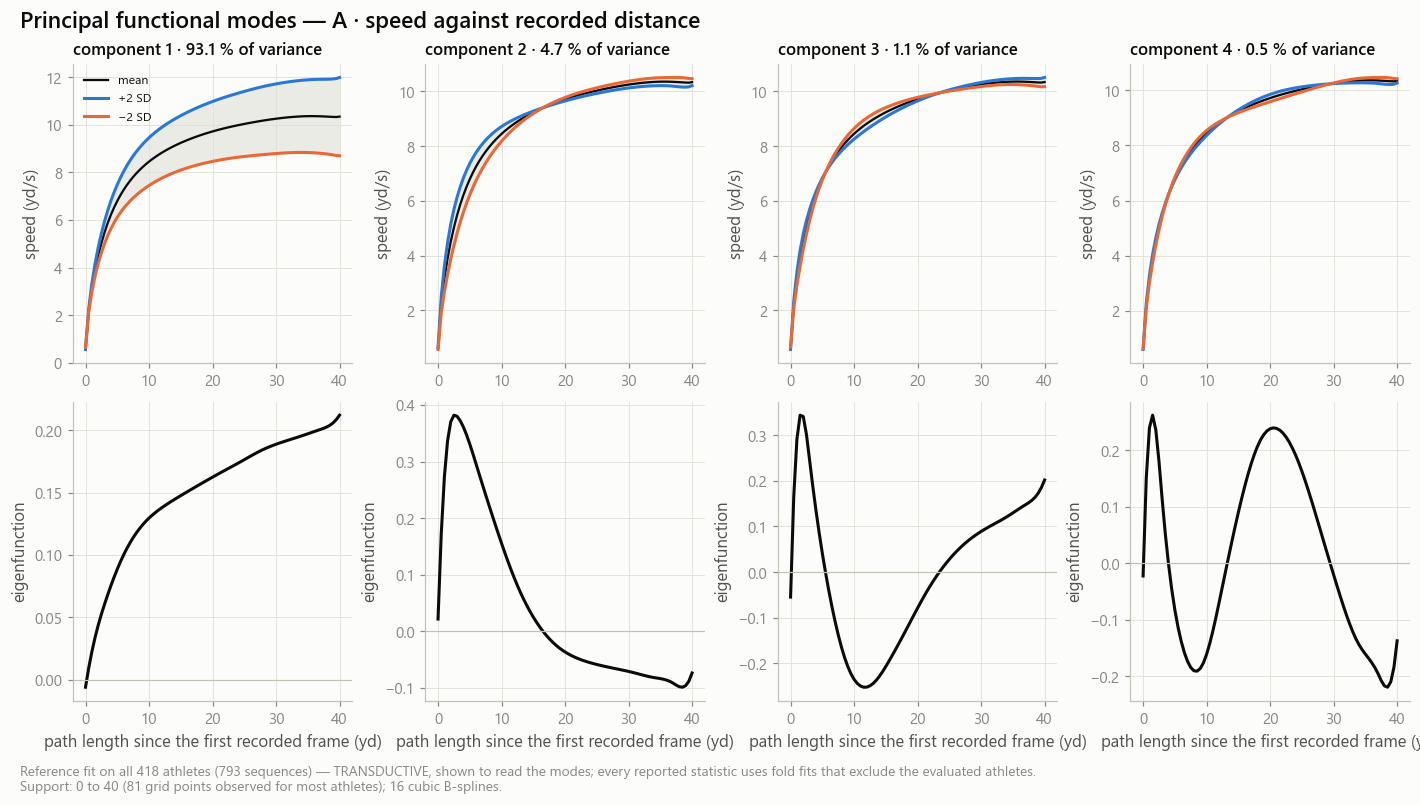

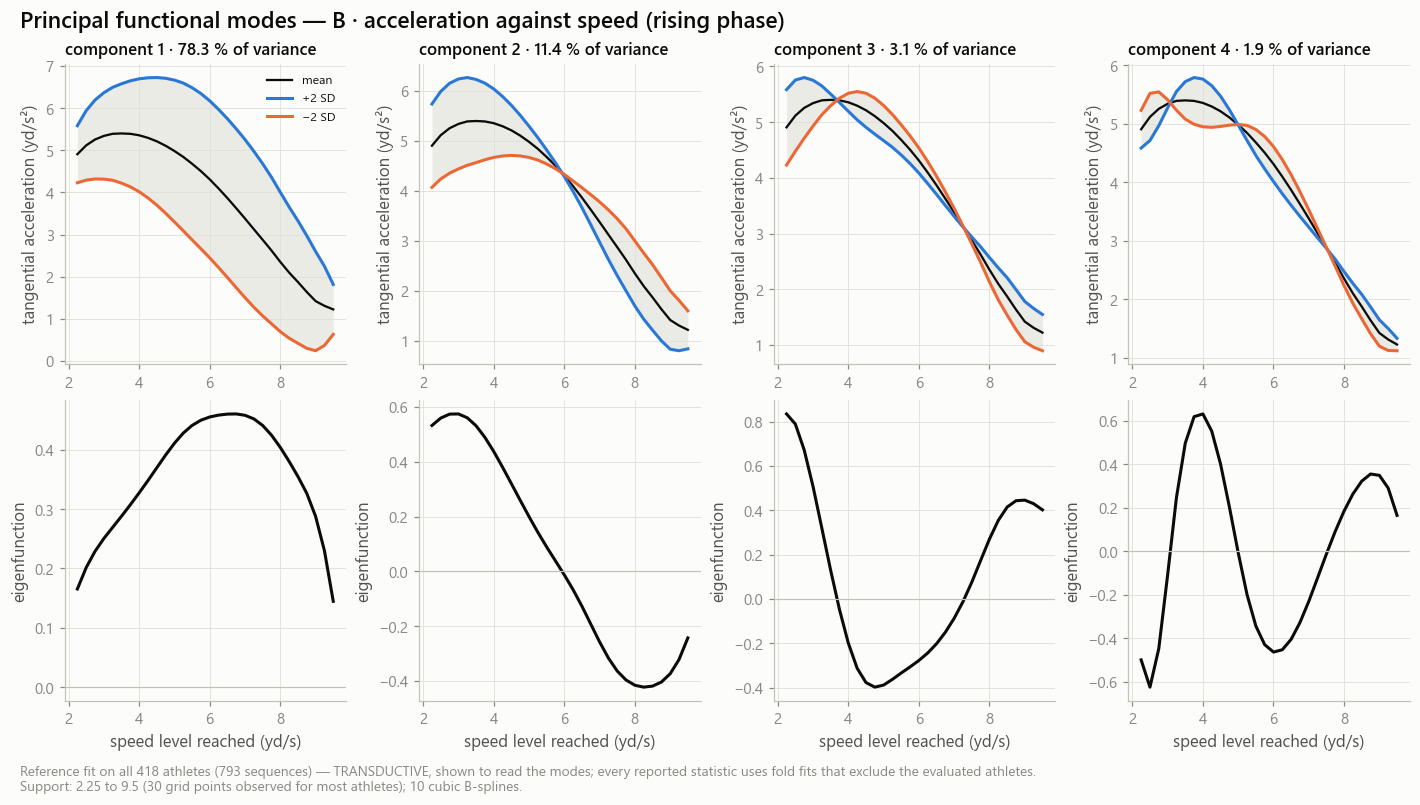

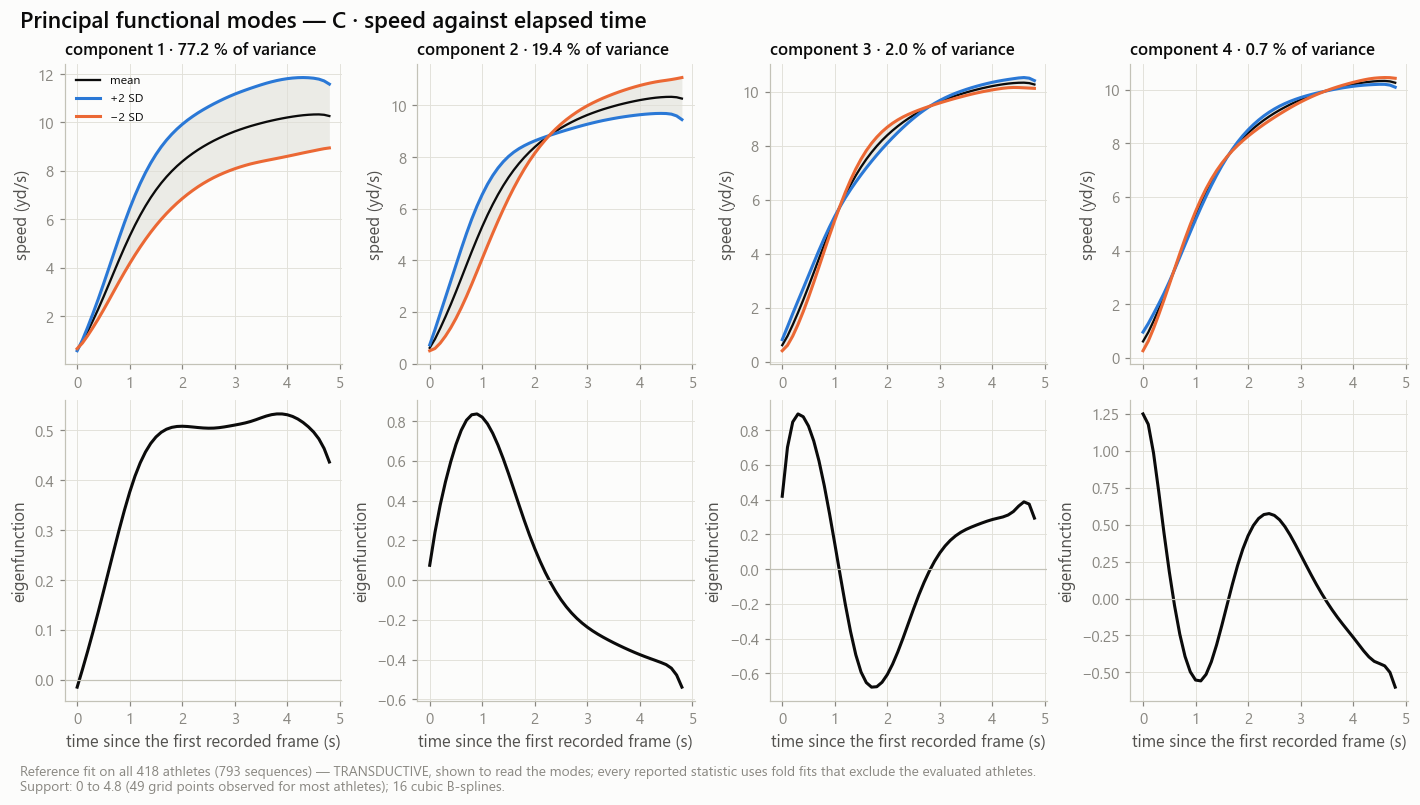

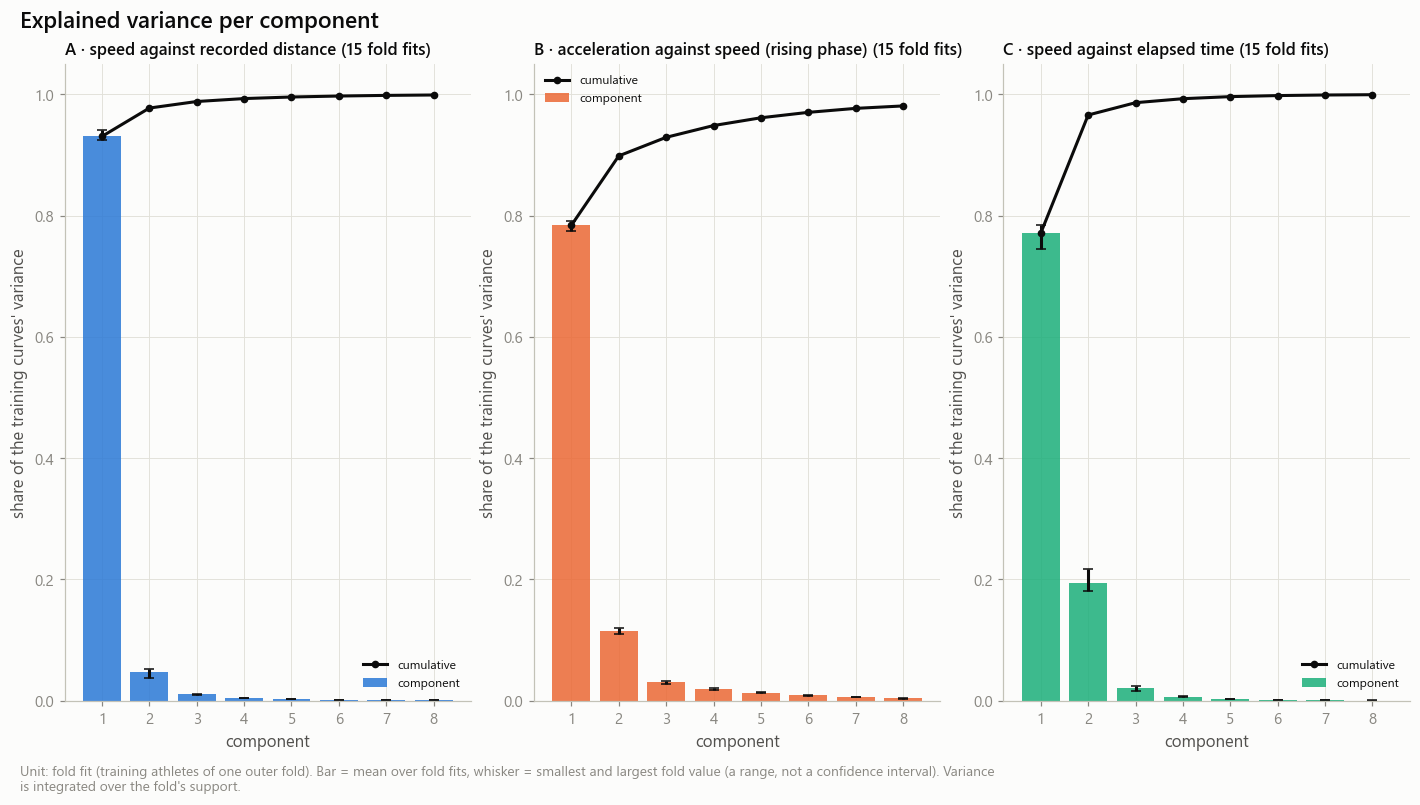

In [10]:
variance = ev[fe.VARIANCE.name]
display(variance.filter(pl.col('representation').is_in(MAIN)))
functions = fit[fe.FUNCTIONS.name]
for name in MAIN:
    reference = models[name]['reference']
    store.show(ff.plot_modes(reference, name), f'AM02_02_modes_{name}',
               {'functions': functions.filter((pl.col('representation') == name) & (pl.col('repeat') == -1))},
               publication=(name == MAIN[0]), source='fpca_functions (reference fit, transductive)',
               n=f'{len(reference.fit_athletes)} athletes')
store.show(ff.plot_explained_variance(variance, MAIN), 'AM02_03_explained_variance', {'variance': variance},
           source='fpca_explained_variance', n=f'{n_repeats * n_folds} fold fits per representation')

## 6 · Reconstruction on held-out athletes

For an attempt of an athlete the fit never saw: $\mathrm{FVE} = 1 - \sum (y - \hat y)^2 / \sum (y - \hat\mu)^2$ and the RMSE, both over the **recorded** grid points only. Intervals resample athletes. The training value is shown beside it; a large gap would mean the components describe the training athletes rather than sprinting.

Reconstruction examples are chosen by rule: the held-out attempts at the 10th, 50th and 90th percentile of the error, and the worst one.

representation,k,n_athletes,n_sequences,n_unscored,fve_heldout,fve_lower,fve_upper,fve_train,fve_fold_min,fve_fold_max,rmse_heldout,rmse_lower,rmse_upper,value_unit
str,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""A_speed_by_distance""",2,418,793,0,0.974672,0.970435,0.978138,0.975134,0.9727,0.977116,0.100867,0.09453,0.108025,"""yd/s"""
"""A_speed_by_distance""",3,418,793,0,0.9855,0.982963,0.987488,0.985902,0.983523,0.988912,0.07632,0.071497,0.08206,"""yd/s"""
"""A_speed_by_distance""",5,418,793,0,0.993213,0.991453,0.994596,0.993587,0.990607,0.995546,0.052214,0.046968,0.058312,"""yd/s"""
"""A_speed_by_distance""",8,418,793,0,0.998152,0.997661,0.998532,0.998232,0.997666,0.998487,0.027249,0.024472,0.030448,"""yd/s"""
"""B_accel_by_speed""",2,418,793,0,0.901737,0.888386,0.912696,0.903019,0.883765,0.920551,0.268284,0.255325,0.284369,"""yd/s²"""
"""B_accel_by_speed""",3,418,793,0,0.933013,0.924105,0.94174,0.9347,0.922618,0.945899,0.221511,0.211182,0.233412,"""yd/s²"""
"""B_accel_by_speed""",5,418,793,0,0.964133,0.959267,0.968688,0.96495,0.957688,0.971488,0.162087,0.156601,0.167583,"""yd/s²"""
"""B_accel_by_speed""",8,418,793,0,0.983409,0.980962,0.98562,0.983571,0.97973,0.986567,0.110238,0.106291,0.114322,"""yd/s²"""
"""C_speed_by_time""",2,418,793,0,0.962225,0.948866,0.970909,0.96312,0.934311,0.974331,0.152378,0.1308,0.179321,"""yd/s"""


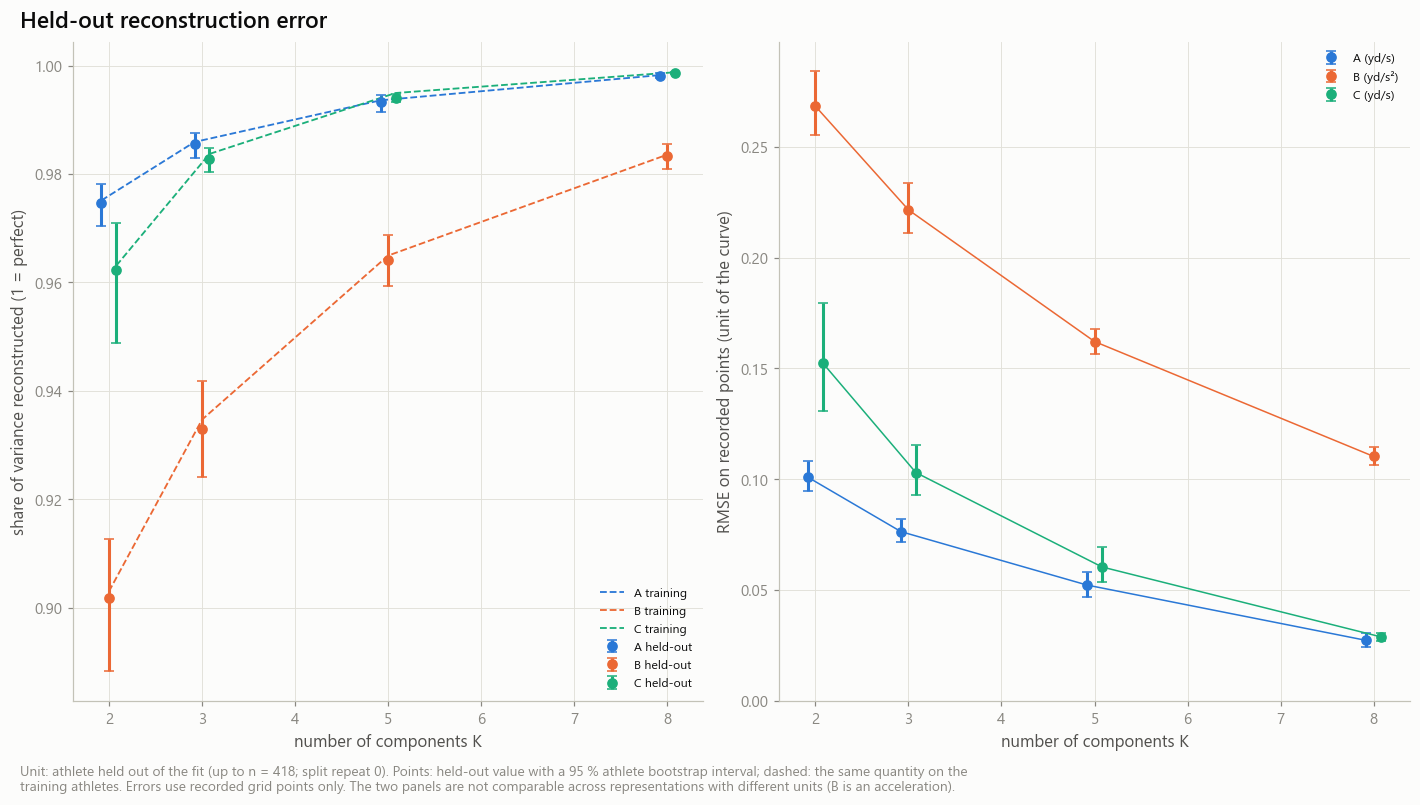

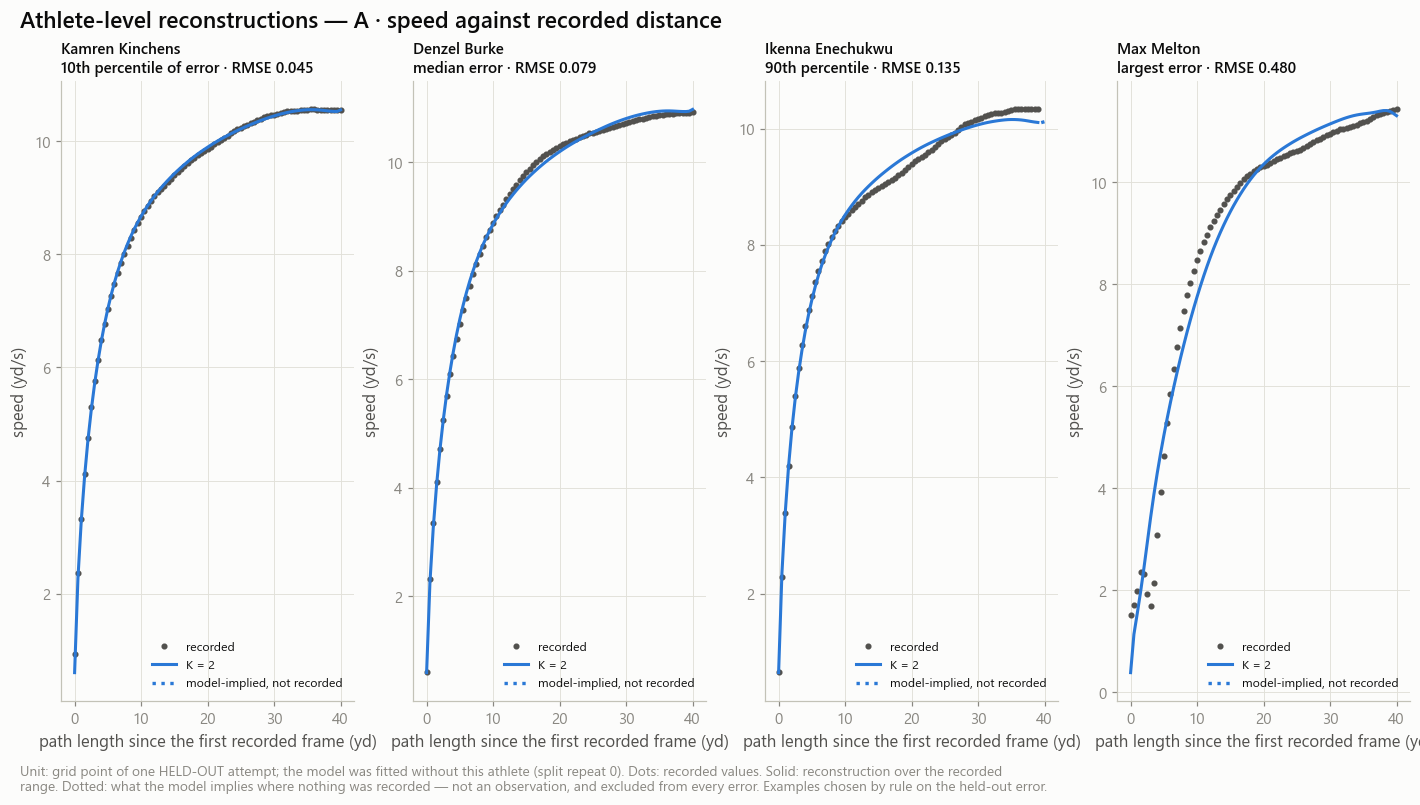

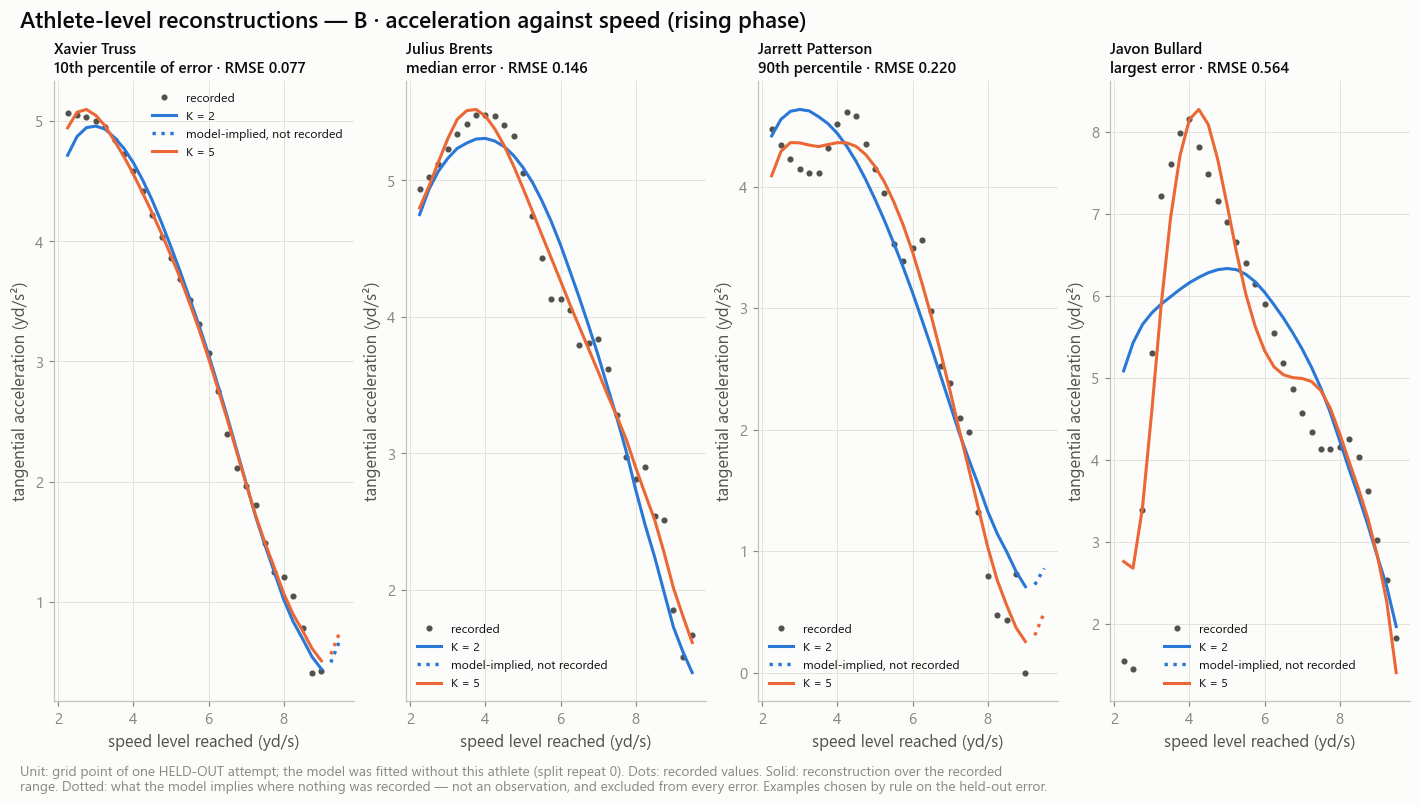

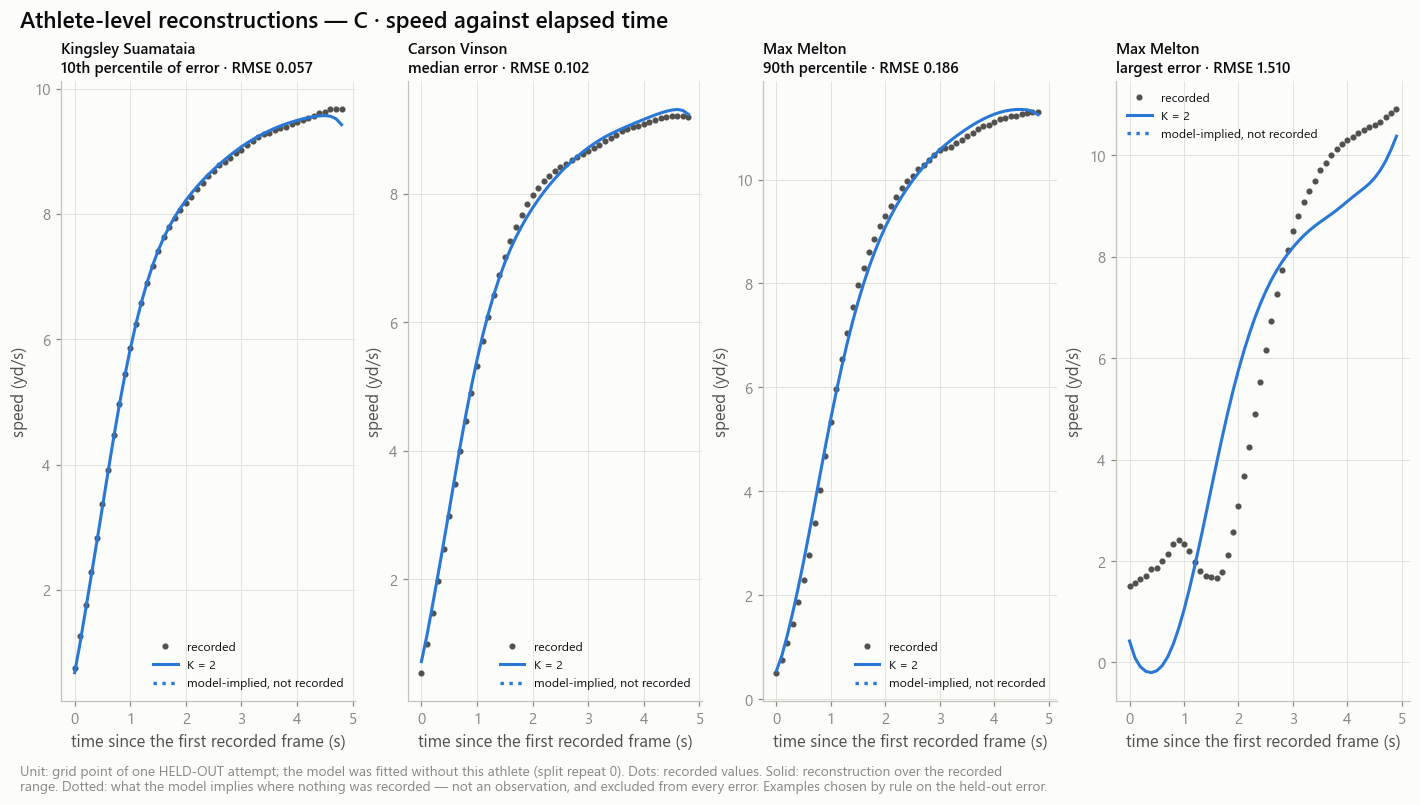

In [11]:
recon = ev[fe.RECON.name]
display(recon.filter(pl.col('representation').is_in(MAIN) & (pl.col('repeat') == 0)).select(
    'representation', 'k', 'n_athletes', 'n_sequences', 'n_unscored', 'fve_heldout', 'fve_lower', 'fve_upper', 'fve_train',
    'fve_fold_min', 'fve_fold_max', 'rmse_heldout', 'rmse_lower', 'rmse_upper', 'value_unit').sort('representation', 'k'))
store.show(ff.plot_heldout_error(recon, MAIN), 'AM02_04_heldout_reconstruction_error', {'reconstruction': recon},
           publication=True, source='fpca_reconstruction_error', n=f'{np.unique(ss.nfl_ids).size} athletes, each held out once')
seq_recon = fit[fe.SEQ_RECON.name]
for name in MAIN:
    examples = ff.reconstruction_examples(seq_recon, name, K[name])
    shown = pl.DataFrame({'seq_id': [e[0] for e in examples], 'fit': [e[1] for e in examples], 'note': [e[2] for e in examples]},
                         schema={'seq_id': pl.String, 'fit': pl.String, 'note': pl.String})
    store.show(ff.plot_reconstructions(curves[name], models[name], examples, sorted({min(fcfg.k_grid), K[name]}), names),
               f'AM02_05_reconstructions_{name}', {'examples': shown}, source='fpca_sequence_reconstruction (held-out)',
               n=f'{len(examples)} held-out attempts')

## 7 · Repeat-attempt reliability

Does an athlete get the same score on his two attempts? Out-of-fold scores, stratified ICC(1) with athletes nested in strata; the outer fold is part of every stratum, so a difference between two fold fits cannot count as a difference between athletes.

| Scope | Athletes are compared … |
|---|---|
| `pooled` | with everyone (inflated by position differences; reference only) |
| `position_adjusted` | inside their position group — **the primary view** |
| `cohort_adjusted`, `position_cohort_adjusted` | inside their draft cohort, and inside position × cohort |
| `position:<group>`, `cohort:<year>` | one group at a time (cohort rows are within position); shown where at least 10 athletes have a repeat |
| `position_adjusted@S2_signal`, `@S3_no_boundary` | within position, on the sequences passing the stricter quality scenarios |

Intervals are athlete bootstraps on split repeat 0. With two attempts per athlete, the within-athlete variance rests on one difference per athlete: small groups (TE) have wide intervals.

**At the benchmark K, split repeat 0**

representation,component,scope,n_athletes_repeat,icc,ci_lower,ci_upper,typical_error,reliability_of_mean
str,i64,str,i64,f64,f64,f64,f64,f64
"""A_speed_by_distance""",1,"""cohort_adjusted""",375,0.988899,0.985398,0.990971,0.414125,0.994118
"""A_speed_by_distance""",1,"""pooled""",375,0.988649,0.985276,0.991066,0.414125,0.993984
"""A_speed_by_distance""",1,"""position_adjusted""",375,0.953262,0.937165,0.962957,0.414125,0.974807
"""A_speed_by_distance""",1,"""position_adjusted@S2_signal""",333,0.962819,0.948664,0.969418,0.374502,0.979339
"""A_speed_by_distance""",1,"""position_adjusted@S3_no_boundary""",254,0.962968,0.946195,0.970477,0.385188,0.977516
"""A_speed_by_distance""",1,"""position_cohort_adjusted""",375,0.9548,0.930133,0.958145,0.414125,0.975654
"""A_speed_by_distance""",2,"""cohort_adjusted""",375,0.27953,0.092647,0.441388,0.696005,0.423981
"""A_speed_by_distance""",2,"""pooled""",375,0.344956,0.204676,0.496193,0.696005,0.499764
"""A_speed_by_distance""",2,"""position_adjusted""",375,0.357969,0.194068,0.469359,0.696005,0.514034


**Within each position group** (ICC; eligible athletes with a repeat in the second table)

representation,component,position:DB,position:DL,position:OL,position:TE,position:WR
str,i64,f64,f64,f64,f64,f64
"""A_speed_by_distance""",1,0.883746,0.987511,0.945371,0.945767,0.865665
"""A_speed_by_distance""",2,0.240325,0.685025,0.574056,0.187528,0.164891
"""B_accel_by_speed""",1,0.569426,0.898803,0.540518,0.718841,0.146237
"""B_accel_by_speed""",2,0.412212,0.491421,0.44438,0.118019,0.346433
"""B_accel_by_speed""",3,0.267099,0.250698,0.22574,0.290811,0.461783
"""B_accel_by_speed""",4,0.157786,0.066025,-0.102281,0.259033,0.457086
"""B_accel_by_speed""",5,0.070695,0.184172,0.010411,0.602045,0.227186
"""C_speed_by_time""",1,0.10782,0.935897,0.787538,0.525868,0.254172
"""C_speed_by_time""",2,0.392801,0.622546,0.509736,0.078211,0.218328


representation,component,position:DB,position:DL,position:OL,position:TE,position:WR
str,i64,i64,i64,i64,i64,i64
"""A_speed_by_distance""",1,93,84,84,32,82
"""A_speed_by_distance""",2,93,84,84,32,82
"""B_accel_by_speed""",1,93,84,84,32,82
"""B_accel_by_speed""",2,93,84,84,32,82
"""B_accel_by_speed""",3,93,84,84,32,82
"""B_accel_by_speed""",4,93,84,84,32,82
"""B_accel_by_speed""",5,93,84,84,32,82
"""C_speed_by_time""",1,93,84,84,32,82
"""C_speed_by_time""",2,93,84,84,32,82


**Within each draft cohort** (within position; ICC, then eligible athletes)

representation,component,cohort:2023,cohort:2024,cohort:2025
str,i64,f64,f64,f64
"""A_speed_by_distance""",1,0.967799,0.923522,0.964553
"""A_speed_by_distance""",2,0.387602,0.261754,0.259852
"""B_accel_by_speed""",1,0.796567,0.329987,0.728669
"""B_accel_by_speed""",2,0.458743,0.277845,0.231734
"""B_accel_by_speed""",3,0.354523,0.121047,0.275462
"""B_accel_by_speed""",4,0.107614,0.191031,0.132654
"""B_accel_by_speed""",5,0.155397,0.094715,0.043739
"""C_speed_by_time""",1,0.286425,0.486753,0.592377
"""C_speed_by_time""",2,0.426581,0.294773,0.123516


representation,component,cohort:2023,cohort:2024,cohort:2025
str,i64,i64,i64,i64
"""A_speed_by_distance""",1,124,122,129
"""A_speed_by_distance""",2,124,122,129
"""B_accel_by_speed""",1,124,122,129
"""B_accel_by_speed""",2,124,122,129
"""B_accel_by_speed""",3,124,122,129
"""B_accel_by_speed""",4,124,122,129
"""B_accel_by_speed""",5,124,122,129
"""C_speed_by_time""",1,124,122,129
"""C_speed_by_time""",2,124,122,129


**Does the estimate move with the split?** position-adjusted ICC per split repeat

representation,component,0,1,2
str,i64,f64,f64,f64
"""A_speed_by_distance""",1,0.953262,0.953117,0.952606
"""A_speed_by_distance""",2,0.357969,0.350731,0.357889
"""B_accel_by_speed""",1,0.534109,0.531885,0.533788
"""B_accel_by_speed""",2,0.409325,0.403021,0.4136
"""B_accel_by_speed""",3,0.310254,0.326582,0.326803
"""B_accel_by_speed""",4,0.187617,0.175663,0.154992
"""B_accel_by_speed""",5,0.175786,0.141708,0.17364
"""C_speed_by_time""",1,0.417478,0.418083,0.420626
"""C_speed_by_time""",2,0.370222,0.362058,0.373816


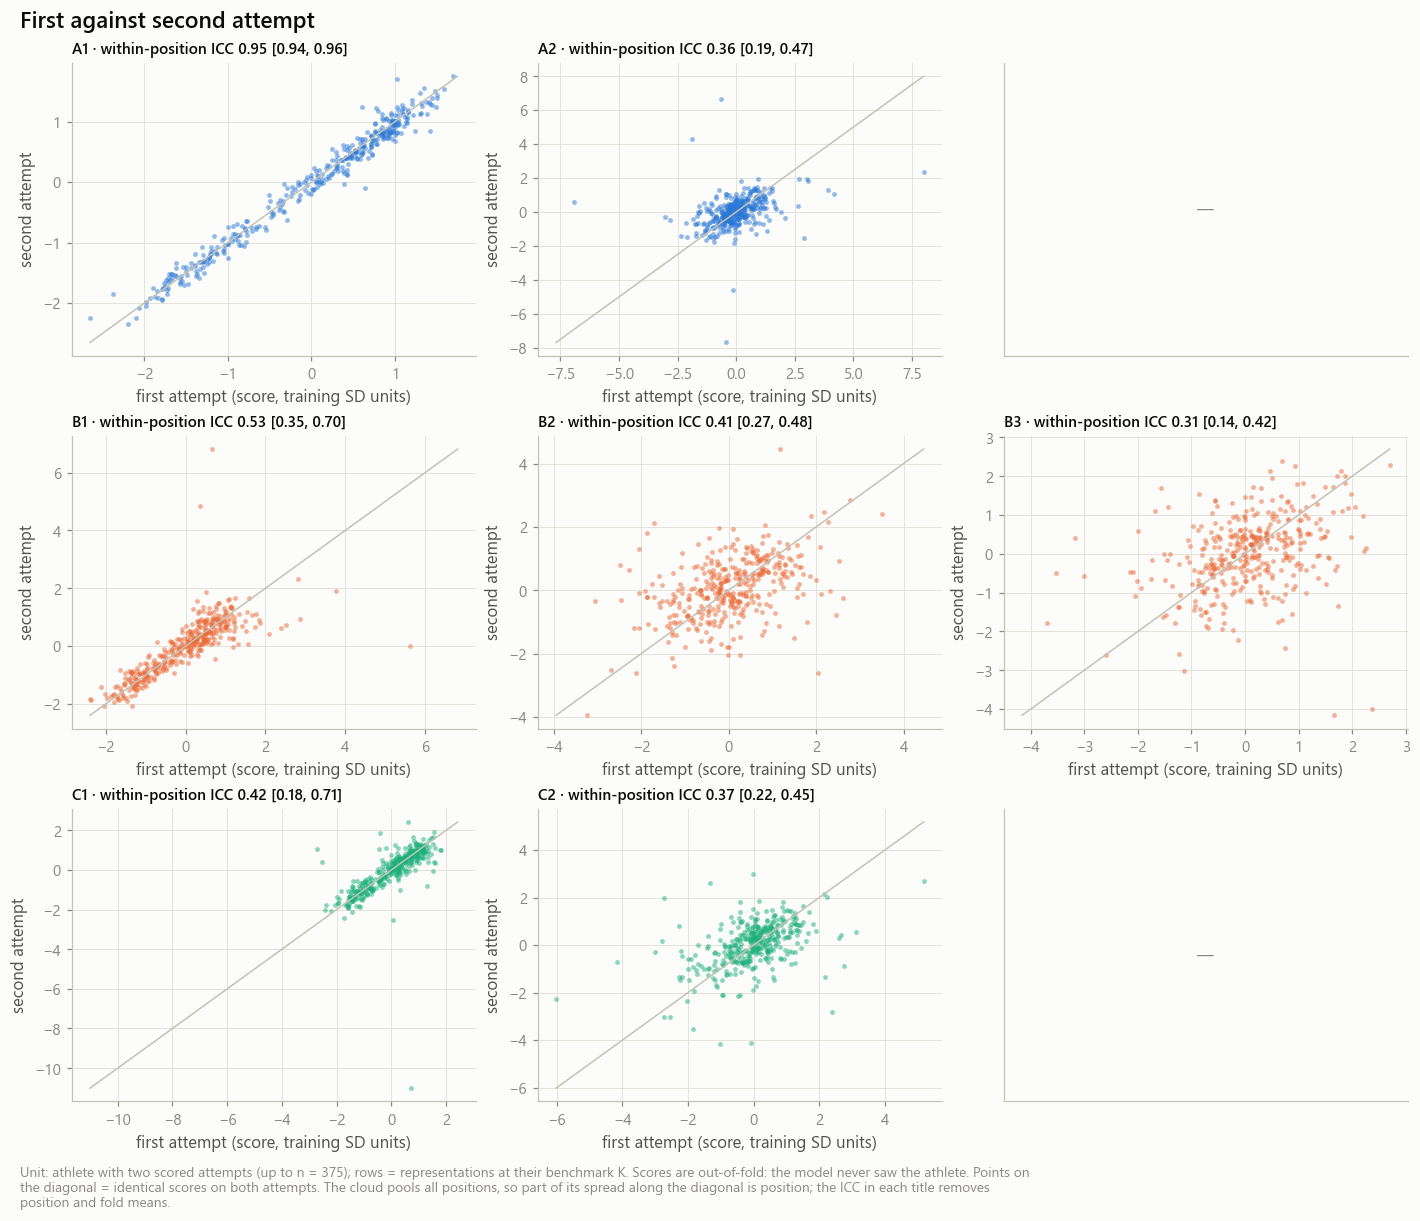

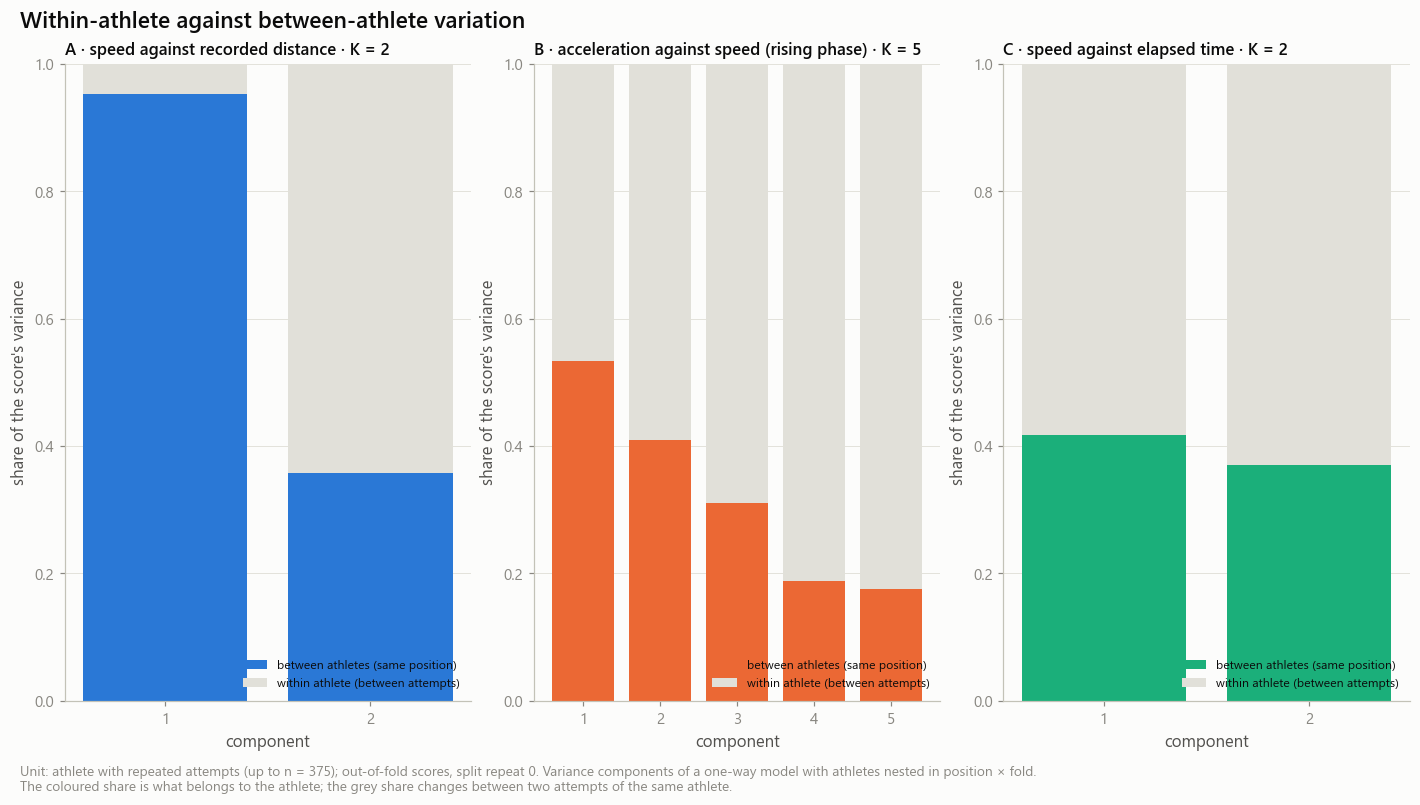

In [12]:
rel = ev[fe.RELIABILITY.name]
rel0 = rel.filter(at_k & (pl.col('repeat') == 0))
general = ['pooled', 'position_adjusted', 'cohort_adjusted', 'position_cohort_adjusted', 'position_adjusted@S2_signal',
           'position_adjusted@S3_no_boundary']
display(Markdown('**At the benchmark K, split repeat 0**'))
display(rel0.filter(pl.col('scope').is_in(general)).select(
    'representation', 'component', 'scope', 'n_athletes_repeat', 'icc', 'ci_lower', 'ci_upper', 'typical_error',
    'reliability_of_mean').sort('representation', 'component', 'scope'))
display(Markdown('**Within each position group** (ICC; eligible athletes with a repeat in the second table)'))
by_position = rel0.filter(pl.col('scope').str.starts_with('position:'))
display(by_position.pivot(on='scope', index=['representation', 'component'], values='icc').sort('representation', 'component'))
display(by_position.pivot(on='scope', index=['representation', 'component'], values='n_athletes_repeat').sort('representation', 'component'))
display(Markdown('**Within each draft cohort** (within position; ICC, then eligible athletes)'))
by_cohort = rel0.filter(pl.col('scope').str.starts_with('cohort:'))
display(by_cohort.pivot(on='scope', index=['representation', 'component'], values='icc').sort('representation', 'component'))
display(by_cohort.pivot(on='scope', index=['representation', 'component'], values='n_athletes_repeat').sort('representation', 'component'))
display(Markdown('**Does the estimate move with the split?** position-adjusted ICC per split repeat'))
display(rel.filter(at_k & (pl.col('scope') == 'position_adjusted')).pivot(
    on='repeat', index=['representation', 'component'], values='icc').sort('representation', 'component'))

scores = fit[fe.SCORES.name]
store.show(ff.plot_attempt_scores(scores, windows, gate, K), 'AM02_06_first_vs_second_attempt', {'reliability': rel0},
           publication=True, source='fpca_attempt_scores (out-of-fold)', n='athletes with two scored attempts')
store.show(ff.plot_variance_components(rel, K), 'AM02_07_within_vs_between_variation',
           {'reliability': rel0.filter(pl.col('scope') == 'position_adjusted')}, source='fpca_reliability',
           n='athletes with a repeat')

## 8 · Stopwatch redundancy and body measurements

Unit: athlete (mean of his out-of-fold attempt scores). Within position:

- Spearman correlation of each component with the official forty and the official 10-yard split;
- $R^2$ of the component on both official times together — the share the stopwatch already explains;
- `reliable_unique_share` = reliability of the athlete mean − that $R^2$ (floored at 0): a lower bound of the reproducible variance the stopwatch does not explain, as in the sprint rescue;
- the same associations with Combine weight and height.

The grey squares of the figure are the handcrafted forty features of the executed sprint rescue (full run only), for scale: `p95_speed` is highly repeatable and redundant with the forty; the acceleration features are neither.

**Official times, within position** (Spearman per official time; R² for both together)

representation,component,target,n_athletes,spearman,spearman_lower,spearman_upper,r2,r2_lower,r2_upper
str,i64,str,i64,f64,f64,f64,f64,f64,f64
"""A_speed_by_distance""",1,"""cmb_forty""",418,-0.930249,-0.942158,-0.915996,null,null,null
"""A_speed_by_distance""",1,"""cmb_forty+cmb_ten_yd_split""",418,null,null,null,0.916159,0.899142,0.930769
"""A_speed_by_distance""",1,"""cmb_ten_yd_split""",418,-0.599185,-0.657588,-0.533623,null,null,null
"""A_speed_by_distance""",2,"""cmb_forty""",418,0.127711,0.031723,0.221364,null,null,null
"""A_speed_by_distance""",2,"""cmb_forty+cmb_ten_yd_split""",418,null,null,null,0.020097,0.00352,0.056296
"""A_speed_by_distance""",2,"""cmb_ten_yd_split""",418,0.036362,-0.060227,0.132276,null,null,null
"""B_accel_by_speed""",1,"""cmb_forty""",418,-0.606001,-0.66362,-0.541235,null,null,null
"""B_accel_by_speed""",1,"""cmb_forty+cmb_ten_yd_split""",418,null,null,null,0.408358,0.328117,0.509833
"""B_accel_by_speed""",1,"""cmb_ten_yd_split""",418,-0.450469,-0.524093,-0.370162,null,null,null


**Body measurements, within position**

representation,component,target,n_athletes,spearman,spearman_lower,spearman_upper,r2,r2_lower,r2_upper
str,i64,str,i64,f64,f64,f64,f64,f64,f64
"""A_speed_by_distance""",1,"""cmb_combine_height""",418,-0.139057,-0.232321,-0.043259,null,null,null
"""A_speed_by_distance""",1,"""cmb_combine_weight""",418,-0.390175,-0.46892,-0.305277,null,null,null
"""A_speed_by_distance""",1,"""cmb_combine_weight+cmb_combine_height""",418,null,null,null,0.312718,0.213654,0.398131
"""A_speed_by_distance""",2,"""cmb_combine_height""",418,-0.01732,-0.113509,0.07919,null,null,null
"""A_speed_by_distance""",2,"""cmb_combine_weight""",418,0.071651,-0.024899,0.166876,null,null,null
"""A_speed_by_distance""",2,"""cmb_combine_weight+cmb_combine_height""",418,null,null,null,0.003824,0.00024,0.023527
"""B_accel_by_speed""",1,"""cmb_combine_height""",418,-0.082969,-0.177924,0.013517,null,null,null
"""B_accel_by_speed""",1,"""cmb_combine_weight""",418,-0.265709,-0.353046,-0.173782,null,null,null
"""B_accel_by_speed""",1,"""cmb_combine_weight+cmb_combine_height""",418,null,null,null,0.13462,0.078776,0.207451


**Pooled over positions** (reference only: position drives both the score and the official time)

representation,component,cmb_forty,cmb_ten_yd_split
str,i64,f64,f64
"""A_speed_by_distance""",1,-0.981909,-0.90136
"""A_speed_by_distance""",2,0.075336,0.034158
"""B_accel_by_speed""",1,-0.877485,-0.834101
"""B_accel_by_speed""",2,0.320471,0.278608
"""B_accel_by_speed""",3,-0.277064,-0.229759
"""B_accel_by_speed""",4,-0.15625,-0.147152
"""B_accel_by_speed""",5,-0.187065,-0.191939
"""C_speed_by_time""",1,-0.882313,-0.817796
"""C_speed_by_time""",2,0.473883,0.423679


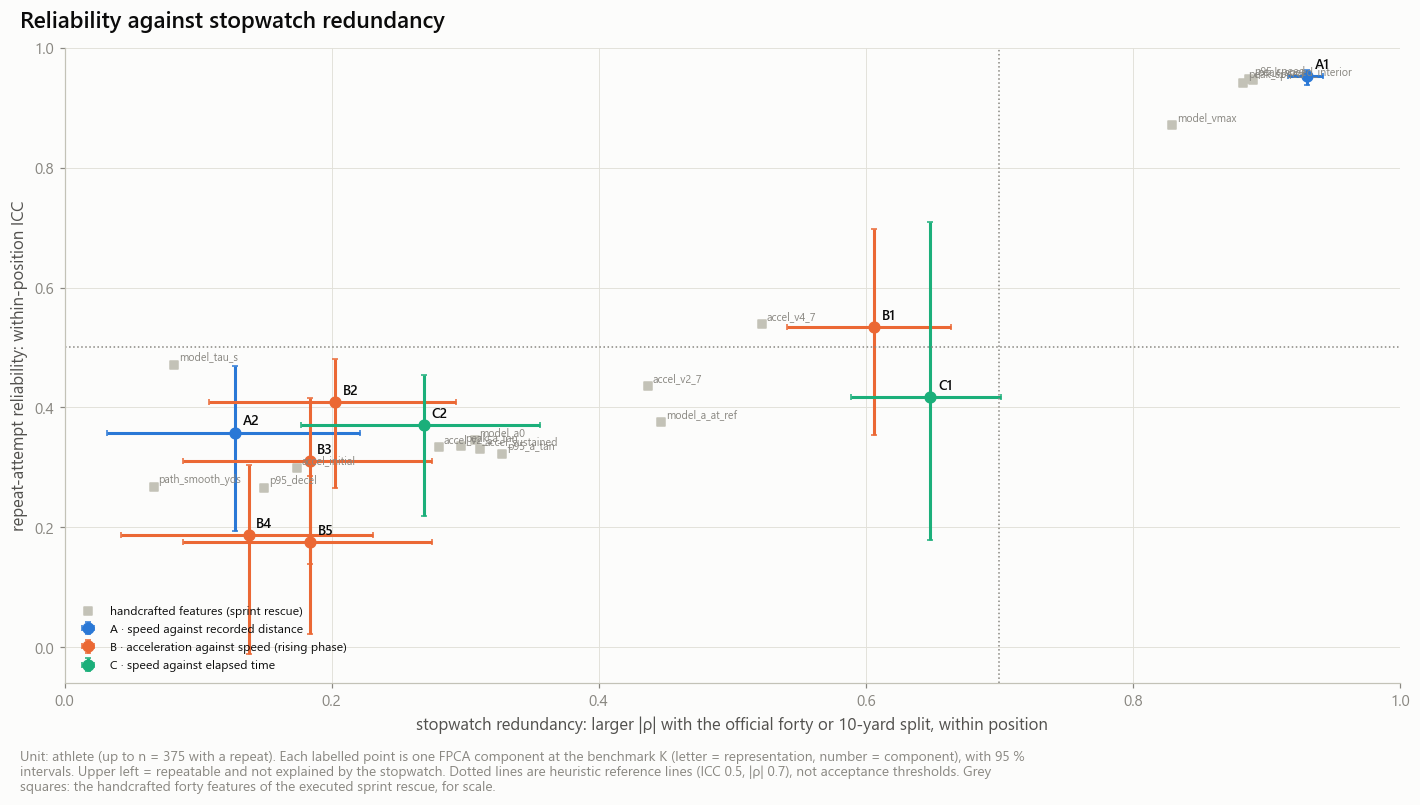

In [13]:
red, body = ev[fe.REDUNDANCY.name], ev[fe.BODY.name]
within = at_k & (pl.col('repeat') == 0) & (pl.col('scope') == 'position_adjusted')
display(Markdown('**Official times, within position** (Spearman per official time; R² for both together)'))
display(red.filter(within).select('representation', 'component', 'target', 'n_athletes', 'spearman', 'spearman_lower',
                                  'spearman_upper', 'r2', 'r2_lower', 'r2_upper').sort('representation', 'component', 'target'))
display(Markdown('**Body measurements, within position**'))
display(body.filter(within).select('representation', 'component', 'target', 'n_athletes', 'spearman', 'spearman_lower',
                                   'spearman_upper', 'r2', 'r2_lower', 'r2_upper').sort('representation', 'component', 'target'))
display(Markdown('**Pooled over positions** (reference only: position drives both the score and the official time)'))
display(red.filter(at_k & (pl.col('repeat') == 0) & (pl.col('scope') == 'pooled') & pl.col('spearman').is_not_null()).pivot(
    on='target', index=['representation', 'component'], values='spearman').sort('representation', 'component'))

rescue_reference = None
if not controls.smoke:        # the executed sprint rescue is a full-run artifact: never mixed into a smoke figure
    from nflbdb.research.sprint_rescue import redundancy as rescue_redundancy

    rescue_store = amd.AdvInputs(cfg, acfg).rescue
    if rescue_store.exists(rescue_redundancy.SCREEN):
        rescue_reference = rescue_store.read(rescue_redundancy.SCREEN)
store.show(ff.plot_reliability_vs_redundancy(gate, fcfg, rescue_reference), 'AM02_08_reliability_vs_stopwatch_redundancy',
           {'gate': gate}, publication=True, source='fpca_component_gate', n='athletes with a repeat and official times')

## 9 · Do the components follow the recording?

Recording duration, first-frame speed, the censoring flags, tracking noise and the share of the support an attempt covers describe the **recording**, not the athlete.

- **Within athlete** (the sharper test): attempt 2 − attempt 1 of a score against attempt 2 − attempt 1 of each variable. The athlete is the same on both attempts; only the recording changed. `window_joint` is the share of that change explained by first-frame speed, duration and frames after the peak together.
- **Between athletes**: athlete means, position removed. `draft_cohort` is the share explained by the cohort within position; cohorts differ in tracking noise, so a large value means the component separates recording years.

A component with a high ICC and a high window share is repeatable only where the recording happens to repeat.

**Shares explained** (R² with a 95 % athlete bootstrap interval)

representation,component,variable,level,n_athletes,r2,r2_lower,r2_upper
str,i64,str,str,i64,f64,f64,f64
"""A_speed_by_distance""",1,"""draft_cohort""","""between_athletes""",418,0.001429,0.000155,0.018894
"""A_speed_by_distance""",2,"""draft_cohort""","""between_athletes""",418,0.086973,0.051185,0.138407
"""B_accel_by_speed""",1,"""draft_cohort""","""between_athletes""",418,0.10595,0.064297,0.16025
"""B_accel_by_speed""",2,"""draft_cohort""","""between_athletes""",418,0.146432,0.105627,0.202282
"""B_accel_by_speed""",3,"""draft_cohort""","""between_athletes""",418,0.121308,0.067973,0.20123
"""B_accel_by_speed""",4,"""draft_cohort""","""between_athletes""",418,0.001503,0.000184,0.022041
"""B_accel_by_speed""",5,"""draft_cohort""","""between_athletes""",418,0.021018,0.004542,0.059944
"""C_speed_by_time""",1,"""draft_cohort""","""between_athletes""",418,0.028217,0.00745,0.080957
"""C_speed_by_time""",2,"""draft_cohort""","""between_athletes""",418,0.120599,0.080799,0.182404


**Within athlete: Spearman between the change of the score and the change of each variable**

representation,component,first_speed,duration_s,frames_after_peak,path_yd,last_speed_frac_of_peak,pos_resid_rms,a_tan_roughness,share_boundary,first_frame_censored,start_above_ref_speed,last_frame_censored,ends_at_peak,boundary_peak,signal_flag,observed_fraction
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""A_speed_by_distance""",1,0.032376,-0.481573,-0.036965,-0.211669,-0.029022,0.010088,0.091009,0.484065,0.004403,-0.037668,-0.018546,-0.031047,-0.008694,0.044993,-0.180987
"""A_speed_by_distance""",2,0.04295,-0.716749,0.022749,-0.369001,-0.028263,-0.140533,0.086086,0.709771,-0.009467,-0.042885,0.008146,0.023716,-0.026692,0.075522,-0.236547
"""B_accel_by_speed""",1,0.016741,-0.543277,-0.005363,-0.313227,-0.070612,-0.054864,0.224825,0.54147,-0.01465,-0.015306,-0.035053,0.021003,0.039979,0.185867,-0.12378
"""B_accel_by_speed""",2,-0.032847,-0.464189,-0.02671,-0.291437,0.028261,-0.106926,0.186409,0.452291,-0.096189,0.028803,0.009781,0.025483,0.103977,0.060941,-0.160531
"""B_accel_by_speed""",3,-0.121261,-0.082118,-0.005361,0.044184,0.026194,-0.083775,0.035352,0.075402,-0.023857,-0.033508,-0.016502,0.025411,0.023546,-0.056868,-0.007124
"""B_accel_by_speed""",4,0.065961,-0.112354,0.020945,-0.066933,0.061712,-0.147686,-0.087032,0.109201,-0.037981,-0.034059,0.09281,-0.045274,-0.039952,-0.062018,0.000273
"""B_accel_by_speed""",5,0.063357,-0.049403,-0.050317,-0.05441,-0.061547,0.061682,0.073678,0.039418,-0.052062,0.032601,0.000334,0.000972,0.056746,0.027508,-0.103029
"""C_speed_by_time""",1,0.293981,-0.932675,0.002452,-0.331517,0.00032,-0.160254,-0.197445,0.933456,0.191786,-0.027461,0.006929,-0.007566,-0.230673,0.032441,-0.46535
"""C_speed_by_time""",2,0.350706,-0.858277,0.001741,-0.275597,0.05091,-0.1845,-0.255313,0.861985,0.246802,-0.015586,0.055222,0.02015,-0.241144,0.01973,-0.479299


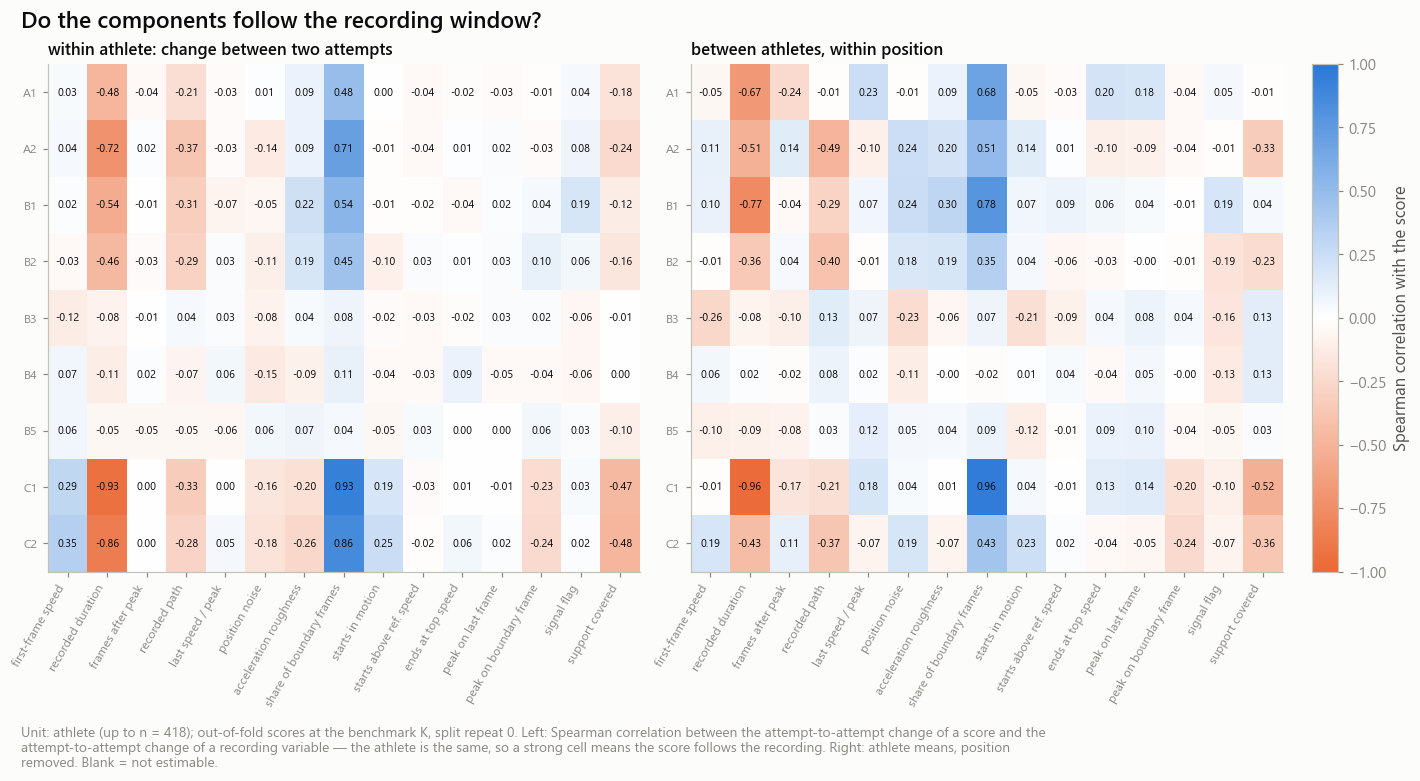

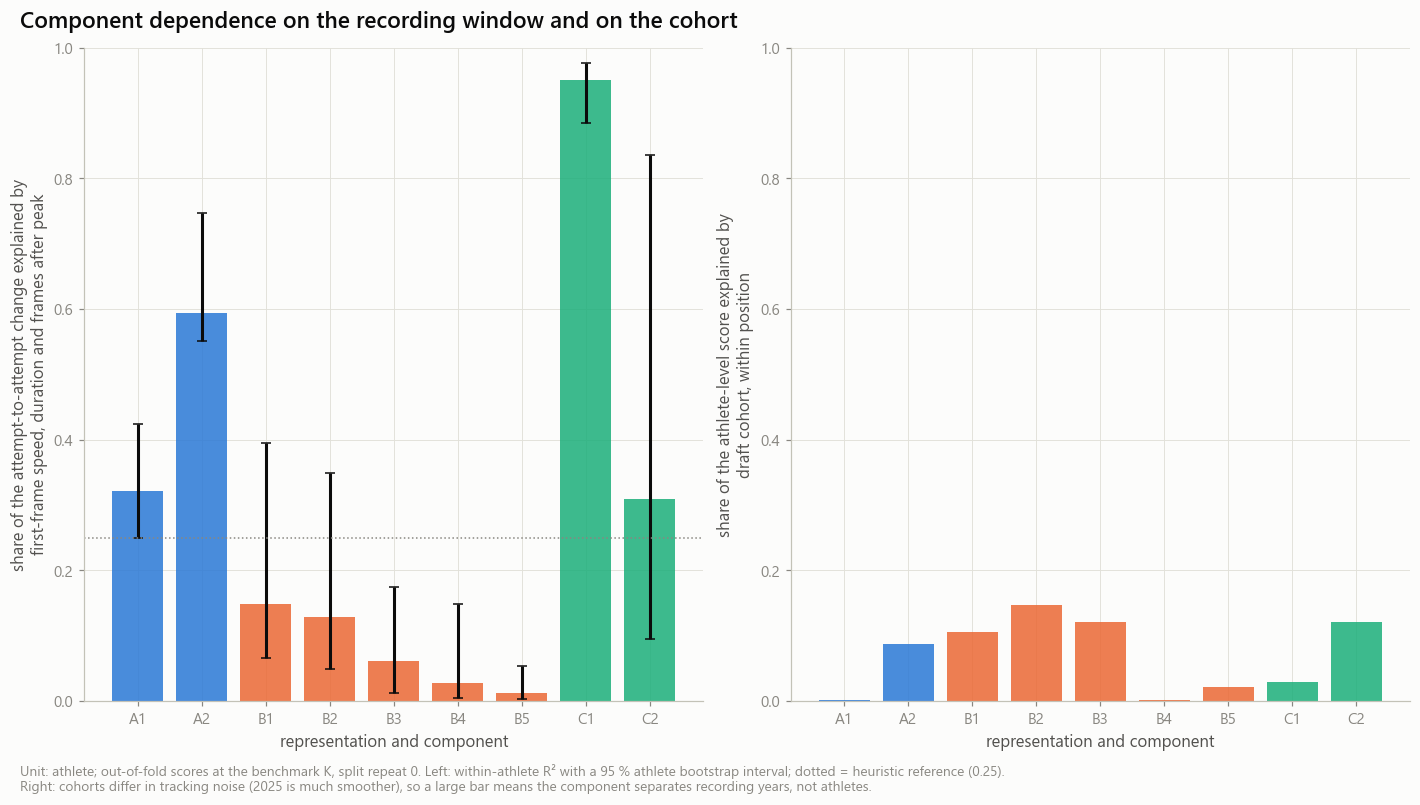

In [14]:
window = ev[fe.WINDOW.name]
display(Markdown('**Shares explained** (R² with a 95 % athlete bootstrap interval)'))
display(window.filter(at_k & pl.col('variable').is_in(['window_joint', 'draft_cohort'])).select(
    'representation', 'component', 'variable', 'level', 'n_athletes', 'r2', 'r2_lower', 'r2_upper').sort(
    'variable', 'representation', 'component'))
display(Markdown('**Within athlete: Spearman between the change of the score and the change of each variable**'))
display(window.filter(at_k & (pl.col('level') == 'within_athlete') & pl.col('spearman').is_not_null()).pivot(
    on='variable', index=['representation', 'component'], values='spearman').sort('representation', 'component'))
store.show(ff.plot_window_heatmap(window, K), 'AM02_09_window_dependence_heatmap', {'window': window.filter(at_k)},
           source='fpca_window_dependence', n='athletes (within-athlete panel: athletes with two scored attempts)')
store.show(ff.plot_nuisance_shares(gate, fcfg), 'AM02_10_window_and_cohort_shares', {'gate': gate},
           source='fpca_component_gate', n='athletes')

## 10 · Sensitivity to the alignment and stability across training folds

- **Alternate alignments.** A′ and C′ move the origin from the first recorded frame to the moment the athlete reaches the reference speed (attempts that start above it have no curve). B′ keeps acceleration on the smoothing-boundary frames. For each component of the main representation: the share of its athlete-level variance reproduced by the scores of the alternate. A component that disappears under the alternate depends on the alignment choice.
- **Fold stability.** Congruence between each fold's eigenfunction and the reference (1 = same shape), and the correlation of athlete scores between split repeats, where an athlete is scored by models trained on different athletes. Smoke mode has a single split repeat, so the second table is then empty.

representation,alternate,k,repeat,component,scope,n_athletes,r2_from_alternate,r2_lower,r2_upper,best_alt_component,best_abs_spearman
str,str,i64,i64,i64,str,i64,f64,f64,f64,i64,f64
"""A_speed_by_distance""","""A_alt_origin_at_ref_speed""",2,0,1,"""pooled""",418,0.999418,0.998901,0.999717,1,0.999181
"""A_speed_by_distance""","""A_alt_origin_at_ref_speed""",2,0,1,"""position_adjusted""",418,0.997606,0.995779,0.998899,1,0.999181
"""A_speed_by_distance""","""A_alt_origin_at_ref_speed""",2,0,2,"""pooled""",418,0.827536,0.761887,0.896083,2,0.928415
"""A_speed_by_distance""","""A_alt_origin_at_ref_speed""",2,0,2,"""position_adjusted""",418,0.830538,0.769787,0.897384,2,0.928415
"""B_accel_by_speed""","""B_alt_boundary_kept""",5,0,1,"""pooled""",418,0.999844,0.999772,0.999906,1,0.990522
"""B_accel_by_speed""","""B_alt_boundary_kept""",5,0,1,"""position_adjusted""",418,0.999605,0.999397,0.999761,1,0.990522
"""B_accel_by_speed""","""B_alt_boundary_kept""",5,0,2,"""pooled""",418,0.99143,0.987908,0.99514,2,0.838402
"""B_accel_by_speed""","""B_alt_boundary_kept""",5,0,2,"""position_adjusted""",418,0.99093,0.98774,0.994741,2,0.838402
"""B_accel_by_speed""","""B_alt_boundary_kept""",5,0,3,"""pooled""",418,0.916102,0.893072,0.941712,4,0.58969


**Reliability of the alternates at their own benchmark K** (position-adjusted, split repeat 0)

representation,component,n_athletes_repeat,icc,ci_lower,ci_upper
str,i64,i64,f64,f64,f64
"""A_alt_origin_at_ref_speed""",1,372,0.959134,0.946545,0.965517
"""A_alt_origin_at_ref_speed""",2,372,0.471612,0.251563,0.643036
"""B_alt_boundary_kept""",1,375,0.491507,0.324388,0.652465
"""B_alt_boundary_kept""",2,375,0.428867,0.284343,0.514434
"""B_alt_boundary_kept""",3,375,0.218002,0.053077,0.344036
"""B_alt_boundary_kept""",4,375,0.072467,-0.085349,0.192483
"""B_alt_boundary_kept""",5,375,0.194975,0.003945,0.319665
"""B_alt_boundary_kept""",6,375,0.165867,0.020495,0.248224
"""B_alt_boundary_kept""",7,375,0.0333,-0.094091,0.118508


**Athlete scores between split repeats** (Pearson; one row per component and pair of repeats)

representation,k,component,repeat_a,repeat_b,n_athletes,pearson
str,i64,i64,i64,i64,i64,f64
"""A_speed_by_distance""",2,1,0,1,418,0.999965
"""A_speed_by_distance""",2,1,0,2,418,0.99991
"""A_speed_by_distance""",2,1,1,2,418,0.999921
"""A_speed_by_distance""",2,2,0,1,418,0.999239
"""A_speed_by_distance""",2,2,0,2,418,0.998786
"""A_speed_by_distance""",2,2,1,2,418,0.999017
"""B_accel_by_speed""",5,1,0,1,418,0.999785
"""B_accel_by_speed""",5,1,0,2,418,0.999812
"""B_accel_by_speed""",5,1,1,2,418,0.999779


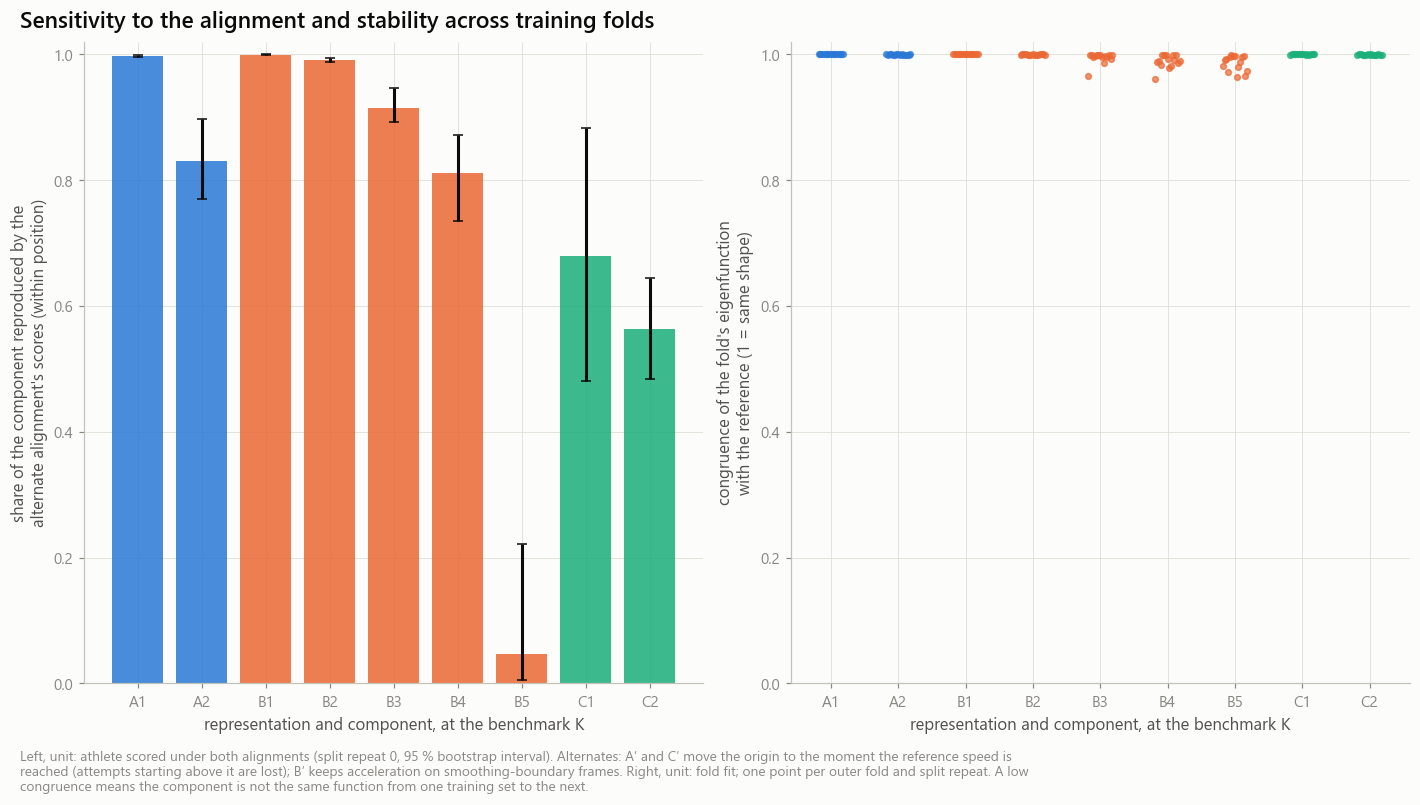

In [15]:
sensitivity, stability, components = ev[fe.SENSITIVITY.name], ev[fe.STABILITY.name], fit[fe.FOLD_COMPONENTS.name]
display(sensitivity.filter(at_k & (pl.col('repeat') == 0)).sort('representation', 'component', 'scope'))
display(Markdown('**Reliability of the alternates at their own benchmark K** (position-adjusted, split repeat 0)'))
alternates = {name: k for name, k in k_all.items() if name not in K}
if alternates:
    at_alt = pl.any_horizontal([(pl.col('representation') == name) & (pl.col('k') == k) for name, k in alternates.items()])
    display(rel.filter(at_alt & (pl.col('repeat') == 0) & (pl.col('scope') == 'position_adjusted')).select(
        'representation', 'component', 'n_athletes_repeat', 'icc', 'ci_lower', 'ci_upper').sort('representation', 'component'))
display(Markdown('**Athlete scores between split repeats** (Pearson; one row per component and pair of repeats)'))
display(stability.filter(at_k).sort('representation', 'component', 'repeat_a', 'repeat_b'))
store.show(ff.plot_sensitivity_and_stability(sensitivity, components, K), 'AM02_11_alignment_sensitivity_and_fold_stability',
           {'sensitivity': sensitivity.filter(at_k), 'fold_components': components}, source='fpca_alignment_sensitivity, fpca_fold_components',
           n=f'athletes scored under both alignments; {n_repeats * n_folds} fold fits')

## 11 · The three representations compared

One row per component at the benchmark K, with the evidence of sections 5 to 10 and four heuristic labels:

| Label | Rule on the 95 % interval |
|---|---|
| `reproducible` | within-position ICC interval entirely above 0.50 (`yes`), entirely below (`no`), otherwise `uncertain` |
| `stopwatch` | interval of the larger \|ρ\| with the official times entirely above 0.70 (`redundant`), entirely below (`not_redundant`) |
| `window` | interval of the within-athlete window share entirely above 0.25 (`window_driven`), entirely below (`not_window_driven`) |
| `status` | `candidate` = reproducible, not redundant, not window-driven; otherwise the first failing label, or `inconclusive` |

The reference lines are conventions (Koo and Li 2016 for the ICC; the sprint-rescue line for redundancy; a proposed line for the window share). The continuous evidence is saved beside every label, so a line can be moved without recomputing anything.

representation,role,alternate_of,k_selected,k_rule,fve_heldout,fve_lower,fve_upper,rmse_heldout,value_unit,n_athletes_scored,n_athletes_repeat,n_components_reproducible,n_components_candidate,max_icc_adj,max_icc_component,r2_forty_from_scores,r2_forty_lower,r2_forty_upper,best_reliable_unique_share,congruence_min,proposed_benchmark
str,str,str,i64,str,f64,f64,f64,f64,str,i64,i64,i64,i64,f64,i64,f64,f64,f64,f64,f64,bool
"""A_speed_by_distance""","""primary""",null,2,"""smallest K with held-out FVE ≥ 0.95""",0.974672,0.970435,0.978138,0.100867,"""yd/s""",418,375,1,0,0.953262,1,0.916237,0.898305,0.931522,0.493937,0.998926,true
"""B_accel_by_speed""","""secondary""",null,5,"""smallest K with held-out FVE ≥ 0.95""",0.964133,0.959267,0.968688,0.162087,"""yd/s²""",418,375,0,0,0.534109,1,0.545277,0.431016,0.74499,0.538314,0.960378,false
"""C_speed_by_time""","""control""",null,2,"""smallest K with held-out FVE ≥ 0.95""",0.962225,0.948866,0.970909,0.152378,"""yd/s""",418,375,0,0,0.417478,1,0.651297,0.41108,0.908268,0.477756,0.998965,false
"""A_alt_origin_at_ref_speed""","""alternate""","""A_speed_by_distance""",2,"""smallest K with held-out FVE ≥ 0.95""",0.98176,0.97784,0.984736,0.084876,"""yd/s""",418,372,1,0,0.959134,1,0.917368,0.898707,0.934759,0.598237,0.997939,false
"""B_alt_boundary_kept""","""alternate""","""B_accel_by_speed""",8,"""smallest K with held-out FVE ≥ 0.95""",0.972298,0.968319,0.975983,0.14778,"""yd/s²""",418,375,0,0,0.491507,1,0.553517,0.442398,0.747903,0.557076,0.754409,false
"""C_alt_origin_at_ref_speed""","""alternate""","""C_speed_by_time""",2,"""smallest K with held-out FVE ≥ 0.95""",0.98266,0.979993,0.9851,0.087863,"""yd/s""",418,372,1,0,0.831071,1,0.909064,0.890081,0.92827,0.411406,0.998827,false


representation,component,explained_ratio,icc_adj,icc_lower,icc_upper,icc_cohort_min,icc_s3,redundancy_abs,r2_stopwatch,reliable_unique_share,r2_body,window_r2_within,cohort_r2,r2_from_alternate,congruence_min,reproducible,stopwatch,window,status
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str
"""A_speed_by_distance""",1,0.930446,0.953262,0.937165,0.962957,0.923522,0.962968,0.930249,0.916159,0.058648,0.312718,0.321688,0.001429,0.997606,0.999954,"""yes""","""redundant""","""uncertain""","""redundant_with_stopwatch"""
"""A_speed_by_distance""",2,0.046714,0.357969,0.194068,0.469359,0.259852,0.425599,0.127711,0.020097,0.493937,0.003824,0.593982,0.086973,0.830538,0.998926,"""no""","""not_redundant""","""window_driven""","""not_repeatable"""
"""B_accel_by_speed""",1,0.783923,0.534109,0.353402,0.69733,0.329987,0.757698,0.606001,0.408358,0.276673,0.13462,0.148536,0.10595,0.999605,0.999707,"""uncertain""","""not_redundant""","""uncertain""","""inconclusive"""
"""B_accel_by_speed""",2,0.114358,0.409325,0.265203,0.480844,0.231734,0.451569,0.202749,0.02966,0.538314,0.011838,0.128691,0.146432,0.99093,0.998402,"""no""","""not_redundant""","""uncertain""","""not_repeatable"""
"""B_accel_by_speed""",3,0.030625,0.310254,0.138969,0.415228,0.121047,0.334654,0.183528,0.042679,0.417757,0.003651,0.060438,0.121308,0.913977,0.965148,"""no""","""not_redundant""","""not_window_driven""","""not_repeatable"""
"""B_accel_by_speed""",4,0.019402,0.187617,-0.010752,0.303939,0.107614,0.167882,0.137893,0.009856,0.294799,0.012587,0.027763,0.001503,0.811574,0.960378,"""no""","""not_redundant""","""not_window_driven""","""not_repeatable"""
"""B_accel_by_speed""",5,0.012833,0.175786,0.022624,0.284976,0.043739,0.150035,0.183829,0.029848,0.258212,0.018623,0.012524,0.021018,0.046291,0.964159,"""no""","""not_redundant""","""not_window_driven""","""not_repeatable"""
"""C_speed_by_time""",1,0.77113,0.417478,0.179597,0.708681,0.286425,0.352692,0.648392,0.451752,0.124451,0.129597,0.95051,0.028217,0.67931,0.999392,"""uncertain""","""uncertain""","""window_driven""","""window_artifact"""
"""C_speed_by_time""",2,0.194579,0.370222,0.219516,0.454442,0.123516,0.389224,0.269157,0.049486,0.477756,0.024548,0.308626,0.120599,0.563736,0.998965,"""no""","""not_redundant""","""uncertain""","""not_repeatable"""


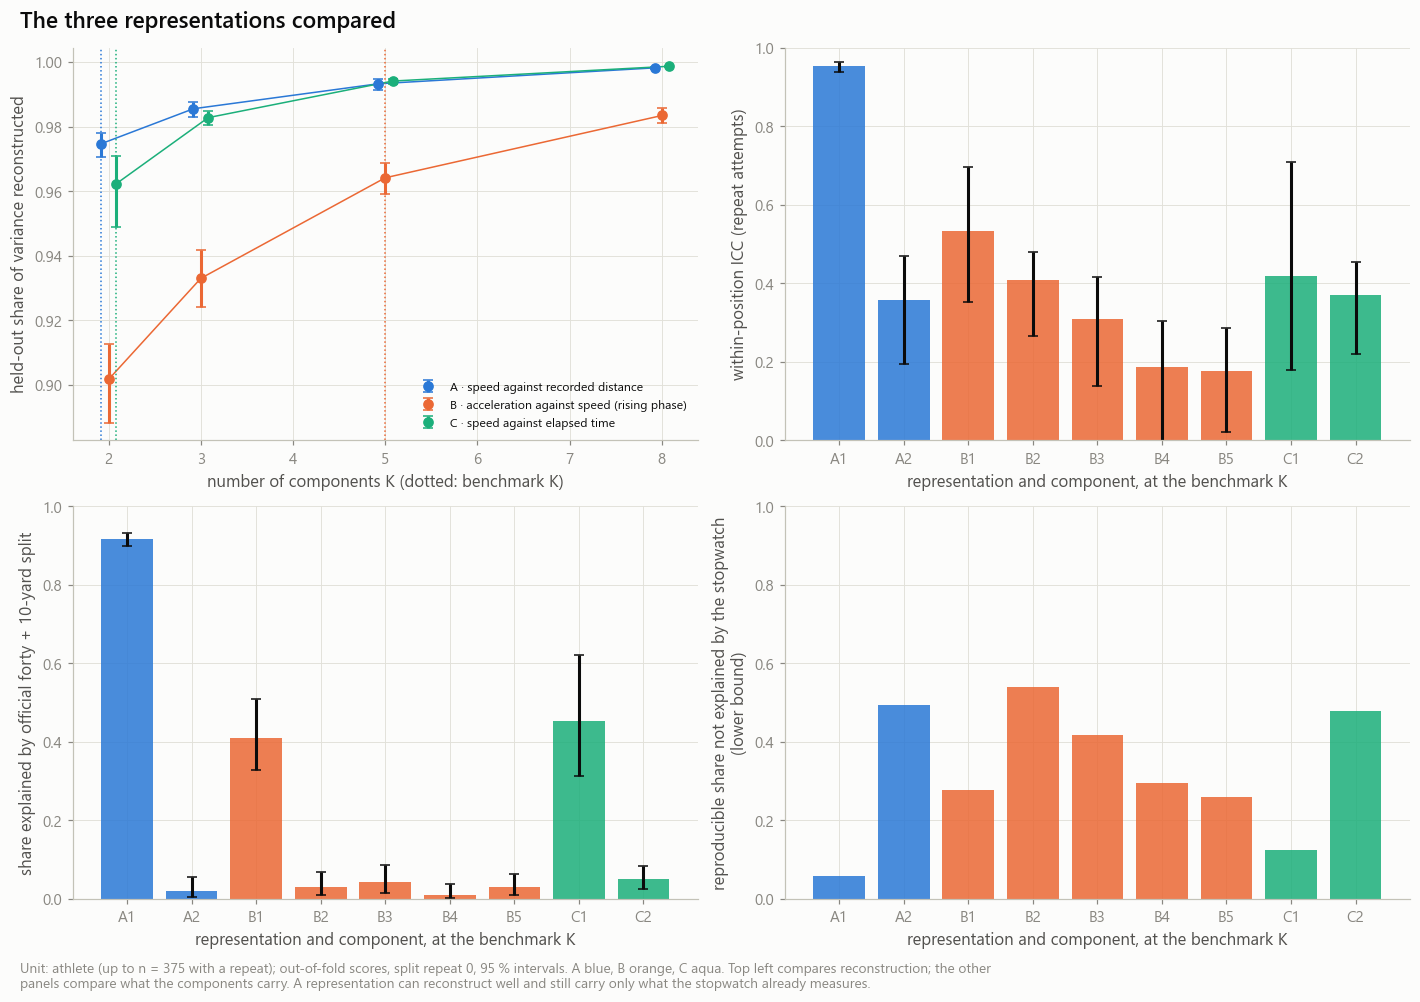

In [16]:
display(rep_summary)
display(gate.filter(pl.col('role') != 'alternate').select(
    'representation', 'component', 'explained_ratio', 'icc_adj', 'icc_lower', 'icc_upper', 'icc_cohort_min', 'icc_s3',
    'redundancy_abs', 'r2_stopwatch', 'reliable_unique_share', 'r2_body', 'window_r2_within', 'cohort_r2',
    'r2_from_alternate', 'congruence_min', 'reproducible', 'stopwatch', 'window', 'status'))
store.show(ff.plot_representation_comparison(rep_summary, gate, recon), 'AM02_12_representation_comparison',
           {'summary': rep_summary, 'gate': gate}, publication=True, source='fpca_representation_summary, fpca_component_gate',
           n='athletes with a repeat')

## 12 · Conclusions

The text below is generated from the saved tables of this run. Nothing in it is written from expectation, and a smoke run says so.

In [17]:
conclusions = fe.conclusions_markdown(rep_summary, gate, fcfg, controls.run_mode)
display(Markdown(conclusions))

_Generated from `fpca_representation_summary` and `fpca_component_gate` of this run (`RUN_MODE = 'full'`). Intervals are 95 %, athlete-level. Labels are heuristic screening labels._

**A · speed against recorded distance** — K = 2 (smallest K with held-out FVE ≥ 0.95); held-out share of variance 0.975 [0.970, 0.978], RMSE 0.101 yd/s; 418 athletes scored, 375 with a repeat.
- Component 1 (93.0 % of variance): within-position ICC 0.95 [0.94, 0.96]; |ρ| with the official times 0.93 [0.92, 0.94]; stopwatch R² 0.92; attempt-to-attempt change explained by the recording window 0.32 [0.25, 0.42] → **redundant_with_stopwatch**.
- Component 2 (4.7 % of variance): within-position ICC 0.36 [0.19, 0.47]; |ρ| with the official times 0.13 [0.03, 0.22]; stopwatch R² 0.02; attempt-to-attempt change explained by the recording window 0.59 [0.55, 0.75] → **not_repeatable**.
- The K scores together explain 0.92 [0.90, 0.93] of the official forty within position; largest reproducible share not explained by the stopwatch: 0.49.

**B · acceleration against speed (rising phase)** — K = 5 (smallest K with held-out FVE ≥ 0.95); held-out share of variance 0.964 [0.959, 0.969], RMSE 0.162 yd/s²; 418 athletes scored, 375 with a repeat.
- Component 1 (78.4 % of variance): within-position ICC 0.53 [0.35, 0.70]; |ρ| with the official times 0.61 [0.54, 0.66]; stopwatch R² 0.41; attempt-to-attempt change explained by the recording window 0.15 [0.07, 0.39] → **inconclusive**.
- Component 2 (11.4 % of variance): within-position ICC 0.41 [0.27, 0.48]; |ρ| with the official times 0.20 [0.11, 0.29]; stopwatch R² 0.03; attempt-to-attempt change explained by the recording window 0.13 [0.05, 0.35] → **not_repeatable**.
- Component 3 (3.1 % of variance): within-position ICC 0.31 [0.14, 0.42]; |ρ| with the official times 0.18 [0.09, 0.28]; stopwatch R² 0.04; attempt-to-attempt change explained by the recording window 0.06 [0.01, 0.17] → **not_repeatable**.
- Component 4 (1.9 % of variance): within-position ICC 0.19 [-0.01, 0.30]; |ρ| with the official times 0.14 [0.04, 0.23]; stopwatch R² 0.01; attempt-to-attempt change explained by the recording window 0.03 [0.00, 0.15] → **not_repeatable**.
- Component 5 (1.3 % of variance): within-position ICC 0.18 [0.02, 0.28]; |ρ| with the official times 0.18 [0.09, 0.28]; stopwatch R² 0.03; attempt-to-attempt change explained by the recording window 0.01 [0.00, 0.05] → **not_repeatable**.
- The K scores together explain 0.55 [0.43, 0.74] of the official forty within position; largest reproducible share not explained by the stopwatch: 0.54.

**C · speed against elapsed time** — K = 2 (smallest K with held-out FVE ≥ 0.95); held-out share of variance 0.962 [0.949, 0.971], RMSE 0.152 yd/s; 418 athletes scored, 375 with a repeat.
- Component 1 (77.1 % of variance): within-position ICC 0.42 [0.18, 0.71]; |ρ| with the official times 0.65 [0.59, 0.70]; stopwatch R² 0.45; attempt-to-attempt change explained by the recording window 0.95 [0.89, 0.98] → **window_artifact**.
- Component 2 (19.5 % of variance): within-position ICC 0.37 [0.22, 0.45]; |ρ| with the official times 0.27 [0.18, 0.36]; stopwatch R² 0.05; attempt-to-attempt change explained by the recording window 0.31 [0.09, 0.84] → **not_repeatable**.
- The K scores together explain 0.65 [0.41, 0.91] of the official forty within position; largest reproducible share not explained by the stopwatch: 0.48.

**Research gate**
1. *Reproducible athlete-level information?* 1 component(s) across the three representations have a within-position ICC interval entirely above 0.5.
2. *Largely explained by the official forty?* 1 component(s) are labelled redundant with the stopwatch (|ρ| interval above 0.7); 0 are reproducible, not redundant and not window-driven.
3. *Explained by noise and censoring?* 1 component(s) are labelled a recording-window artifact (window share interval above 0.25); 6 are not repeatable; 1 are inconclusive.
4. *Low-complexity benchmark for TCN and GRU/LSTM?* Rule-based proposal: **A · speed against recorded distance** with K = 2 (most candidate components, then most reproducible components, then the pre-declared order primary → secondary → control). Review before adopting it.

FPCA is not assumed to beat the official Combine results, and nothing here uses an NFL outcome.

## 13 · Saved artifacts and provenance

CSV for tables, Parquet (with a schema sidecar) for every output, `.npz` for the fitted models. Smoke outputs live under `_sample` and are never read by a full run.

In [18]:
outputs = [ck.WINDOWS, ck.AUDIT, ck.DECISIONS, *fe.FIT_CONTRACTS, *fe.EVAL_CONTRACTS, *fe.GATE_CONTRACTS]
display(pl.DataFrame([{'output': c.name, 'kind': c.kind, 'grain': c.area, 'saved': store.exists(c),
                       'path': cfg.paths.rel(store.parquet(c))} for c in outputs]))
model_dir = store.models_dir / 'fpca'
model_files = sorted(p.name for p in model_dir.glob('*')) if model_dir.is_dir() else []
display(Markdown(f'**Fitted models** ({cfg.paths.rel(model_dir)}): ' + (', '.join(model_files) or 'not saved (SAVE_MODELS is off)')))

basis = {}
for name in curves:
    reference, spec = models[name]['reference'], fp.SPEC[name]
    basis[name] = {'role': spec.role, 'alternate_of': spec.alternate_of, 'value': spec.channel, 'axis': spec.axis_label,
                   'origin': spec.origin, 'boundary_frames_masked': spec.mask_boundary,
                   'grid_first': float(reference.grid_full[0]), 'grid_last': float(reference.grid_full[-1]),
                   'grid_points': int(reference.grid_full.size), 'reference_support_first': float(reference.grid[0]),
                   'reference_support_last': float(reference.grid[-1]), 'reference_support_points': int(reference.support.sum()),
                   'spline_degree': reference.degree, 'n_basis': reference.n_basis, 'knots': reference.knots.tolist(),
                   'benchmark_k': k_all.get(name)}
if controls.save_tables:
    store.write_json('fpca_config_and_basis', {
        'fpca_config': fcfg.params(), 'alignment_config': acfg.params(), 'half_window': half_window, 'representations': basis,
        'note': 'fold-specific supports, noise variances and fit quality are in fpca_fold_fits; fold-specific mean and '
                'eigenfunctions in fpca_functions and in the .npz model files'})
    store.write_json('fpca_experiment_manifest', {
        'notebook': '02_functional_pca_baseline', 'seed': controls.seed, 'model_key': MODEL_KEY,
        'question': 'Can functional representations of Combine sprint trajectories capture repeatable athlete '
                    'characteristics beyond official Combine measurements?',
        'evaluation': 'inductive: every score comes from a fit that excluded the athlete; the reference fit is transductive '
                      'and fixes sign and order only',
        'nfl_outcomes_used': False,
        'tuning_budget': {'compared': {'n_components': list(fcfg.k_grid)},
                          'fixed_not_tuned': ['n_basis per representation', 'min_coverage', 'min_observed_fraction', 'score_method']},
        'n_sequences': ss.n, 'n_athletes': int(np.unique(ss.nfl_ids).size), 'split_repeats': n_repeats, 'outer_folds': n_folds,
        'benchmark_k': k_all, 'validation_checks_passed': int((validation_report['status'] == 'PASS').sum()),
        'blocking_checks_failed': int(audit.filter(pl.col('blocking') & ~pl.col('passed')).height),
        'inputs': {'notebook_00_written_at': previous.get('written_at'),
                   'files': [cfg.paths.rel(p) for p in [*FIT_FILES, store.parquet(amd.MANIFEST), store.parquet(amd.ATHLETES),
                                                         store.parquet(eda.SUMMARY)]]},
        'outputs': {c.name: cfg.paths.rel(store.parquet(c)) for c in outputs}, 'models': model_files,
        'versions': {'numpy': np.__version__, 'polars': pl.__version__},
        'conclusions': conclusions})
    display(Markdown('Wrote `fpca_config_and_basis.json` and `fpca_experiment_manifest.json` beside the datasets.'))

output,kind,grain,saved,path
str,str,str,bool,str
"""sequence_window_flags""","""table""","""sequence""",true,"""warehouse/gold/advanced_movement/sequence_window_flags.parquet"""
"""preprocessing_audit""","""table""","""check""",true,"""warehouse/gold/advanced_movement/preprocessing_audit.parquet"""
"""preprocessing_decisions_final""","""table""","""decision""",true,"""warehouse/gold/advanced_movement/preprocessing_decisions_final.parquet"""
"""fpca_attempt_scores""","""dataset""","""representation × K × split repeat × sequence × component""",true,"""warehouse/gold/advanced_movement/fpca_attempt_scores.parquet"""
"""fpca_sequence_reconstruction""","""dataset""","""representation × K × split repeat × sequence""",true,"""warehouse/gold/advanced_movement/fpca_sequence_reconstruction.parquet"""
"""fpca_fold_fits""","""table""","""representation × K × split repeat × outer fold""",true,"""warehouse/gold/advanced_movement/fpca_fold_fits.parquet"""
"""fpca_fold_components""","""table""","""representation × fit × component""",true,"""warehouse/gold/advanced_movement/fpca_fold_components.parquet"""
"""fpca_functions""","""dataset""","""representation × fit × component × grid point""",true,"""warehouse/gold/advanced_movement/fpca_functions.parquet"""
"""fpca_athlete_scores""","""dataset""","""representation × K × split repeat × athlete × component""",true,"""warehouse/gold/advanced_movement/fpca_athlete_scores.parquet"""


**Fitted models** (artifacts/models/advanced_movement/fpca): A_alt_origin_at_ref_speed.npz, A_speed_by_distance.npz, B_accel_by_speed.npz, B_alt_boundary_kept.npz, C_alt_origin_at_ref_speed.npz, C_speed_by_time.npz, _models.json

Wrote `fpca_config_and_basis.json` and `fpca_experiment_manifest.json` beside the datasets.

## Interpretation
_To be written after the full run. Placeholders — do not fill from expectation._

- **Modes:** _what the first components of A, B and C change in the curve (level, early rise, late rise), and whether the first mode is speed level._
- **Reconstruction:** _how many components the held-out curves need; whether training and held-out values differ._
- **Reliability:** _which components are repeatable within position, in every cohort, and under the stricter quality scenarios._
- **Stopwatch:** _which repeatable components the official forty and 10-yard split already explain, and what is left._
- **Recording window:** _which components move with the recording between two attempts of the same athlete._
- **Alignment and folds:** _which components survive the alternate alignment and are the same function in every fold._

## Limitations
- Two attempts per athlete. Within-athlete variance rests on one difference per athlete; intervals inside one position or one cohort are wide.
- The benchmark K is chosen on held-out reconstruction of the outer folds. That uses no outcome, but a later NFL model must choose K inside its inner folds.
- `reliable_unique_share` is a lower bound that assumes the stopwatch explains reproducible variance only.
- Scores are best linear predictions under a missing-at-random view of the unrecorded part. In B, missing high speeds are informative; the support rule limits this and the observed fraction is tested, but not removed.
- The components after the first ones can be close in variance; when two swap order between folds the table `fpca_explained_variance` counts it (`n_reordered`) and the congruence shows it.
- The within-athlete window test detects dependence on the three window variables it uses, linearly. A different artifact of the recording would not be seen by it.
- The pooled first-against-second-attempt figure mixes positions; only the ICC in each panel title removes them.
- Gate labels are heuristics on proposed reference lines. They organise the evidence; they do not decide.

## Next-step decision
_After review of the full run:_
1. Is any component reproducible within position, in every cohort?
2. Is it largely explained by the official forty and 10-yard split?
3. Is it explained by the recording window, censoring or cohort noise?
4. Which representation, with which K, is the benchmark the TCN (notebook 03) and the GRU/LSTM (notebook 04) must beat on the same out-of-fold criteria?

No NFL outcome model is started from this notebook.